# Zadanie 2 — Air Quality

Cieľ: predpovedať koncentráciu oxidu uhoľnatého (`co`, mg/m³) vo vzduchu na základe odoziev chemických senzorov, teploty, vlhkosti a času merania. Ide o **regresiu**, modely hodnotíme pomocou MSE/RMSE a R².

## Časť 1: Príprava dát

### 1.1 Načítanie dát

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8")   # rovnaky styl grafov ako v zadani 1

In [2]:
pd.set_option("display.max_columns", None)
df = pd.read_csv("air_quality.csv")
print(df.shape)
df.head(10)

(9507, 14)


,instant,date,month,hour,weekday,season,sensor_co,sensor_nmhc,sensor_nox,sensor_no2,sensor_o3,temperature,humidity,co
0,1,2004-03-10,3,18,3,spring,1360.0,1046.0,1056.0,1692.0,1268.0,13.6,48.9,2.6
1,2,2004-03-10,3,19,3,spring,1292.0,955.0,1174.0,1559.0,972.0,13.3,47.7,2.0
2,3,2004-03-10,3,20,3,spring,1402.0,939.0,1140.0,1555.0,1074.0,11.9,54.0,2.2
3,4,2004-03-10,3,21,3,spring,1376.0,948.0,1092.0,1584.0,1203.0,11.0,60.0,2.2
4,5,2004-03-10,3,22,3,spring,1272.0,836.0,1205.0,1490.0,1110.0,11.2,59.6,1.6
5,6,2004-03-10,3,23,3,spring,1197.0,750.0,1337.0,1393.0,949.0,11.2,59.2,1.2
6,7,2004-03-11,3,0,4,spring,1185.0,690.0,1462.0,1333.0,733.0,11.3,56.8,1.2
7,8,2004-03-11,3,1,4,spring,1136.0,672.0,1453.0,1333.0,730.0,10.7,60.0,1.0
8,9,2004-03-11,3,2,4,spring,1094.0,609.0,1579.0,1276.0,620.0,10.7,59.7,0.9
9,10,2004-03-11,3,3,4,spring,1010.0,561.0,1705.0,1235.0,501.0,10.3,60.2,0.6


### 1.2 Prieskum dát

Hľadáme chýbajúce hodnoty (`info`, `isna`), duplikáty, outliery (`describe`: min/max porovnáme s popisom stĺpcov v zadaní) a nepovolené hodnoty v kategóriách (`value_counts`). Navyše overíme, či sú stĺpce odvodené z dátumu (`month`, `weekday`, `season`) s dátumom konzistentné.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9507 entries, 0 to 9506
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   instant      9507 non-null   int64  
 1   date         9507 non-null   str    
 2   month        9507 non-null   int64  
 3   hour         9507 non-null   int64  
 4   weekday      9507 non-null   int64  
 5   season       9507 non-null   str    
 6   sensor_co    9139 non-null   float64
 7   sensor_nmhc  9139 non-null   float64
 8   sensor_nox   9139 non-null   float64
 9   sensor_no2   9139 non-null   float64
 10  sensor_o3    9139 non-null   float64
 11  temperature  9139 non-null   float64
 12  humidity     9139 non-null   float64
 13  co           7791 non-null   float64
dtypes: float64(8), int64(4), str(2)
memory usage: 1.0 MB


In [4]:
df.isna().sum()

instant           0
date              0
month             0
hour              0
weekday           0
season            0
sensor_co       368
sensor_nmhc     368
sensor_nox      368
sensor_no2      368
sensor_o3       368
temperature     368
humidity        368
co             1716
dtype: int64

In [5]:
df.describe()

,instant,month,hour,weekday,sensor_co,sensor_nmhc,sensor_nox,sensor_no2,sensor_o3,temperature,humidity,co
count,9507.000000,9507.000000,9507.000000,9507.000000,9139.000000,9139.000000,9139.000000,9139.000000,9139.000000,9139.000000,9139.000000,7791.000000
mean,4681.997896,6.316609,11.505312,3.004313,1099.537696,938.890032,835.880840,1455.834774,1022.488128,18.324817,49.209749,2.151393
std,2700.183276,3.439156,6.925671,2.003228,217.087721,266.843443,257.020988,346.719361,398.596977,8.841871,17.314165,1.452333
min,1.000000,1.000000,0.000000,0.000000,647.000000,383.000000,322.000000,551.000000,221.000000,-1.900000,9.200000,0.100000
25%,2345.500000,3.000000,5.500000,1.000000,936.000000,734.000000,658.000000,1224.500000,731.000000,11.800000,35.800000,1.100000
50%,4683.000000,6.000000,12.000000,3.000000,1063.000000,909.000000,806.000000,1463.000000,962.000000,17.800000,49.500000,1.800000
75%,7016.500000,9.000000,18.000000,5.000000,1231.000000,1117.000000,969.500000,1674.000000,1274.000000,24.400000,62.500000,2.900000
max,9357.000000,12.000000,23.000000,6.000000,2040.000000,2214.000000,2683.000000,2775.000000,2523.000000,44.600000,88.700000,11.900000


In [6]:
# pocet unikatnych hodnot: ukaze identifikatory a stlpce, ktore by pri one-hot kodovani pridali vela stlpcov
df.nunique()

instant        9357
date            391
month            12
hour             24
weekday           7
season            4
sensor_co      1041
sensor_nmhc    1245
sensor_nox     1221
sensor_no2     1603
sensor_o3      1743
temperature     436
humidity        753
co               96
dtype: int64

In [7]:
df["season"].value_counts()

season
spring    2846
summer    2244
autumn    2218
winter    2199
Name: count, dtype: int64

In [8]:
# month a weekday su odvodene z datumu, season z mesiaca: overime, ci si neodporuju
d = pd.to_datetime(df["date"])
print("nezhoda mesiaca s datumom:", (d.dt.month != df["month"]).sum())
print("nezhoda dna v tyzdni s datumom:", ((d.dt.day_of_week + 1) % 7 != df["weekday"]).sum())   # pandas: 0 = pondelok, zadanie: 0 = nedela
pd.crosstab(df["month"], df["season"])

nezhoda mesiaca s datumom: 0
nezhoda dna v tyzdni s datumom: 0


season,autumn,spring,summer,winter
month,,,,
1,0,0,0,752
2,0,0,0,685
3,0,1269,0,0
4,0,821,0,0
5,0,756,0,0
6,0,0,730,0
7,0,0,757,0
8,0,0,757,0
9,731,0,0,0


In [9]:
print("duplicitne riadky:", df.duplicated().sum())
print("duplicitne riadky bez stlpca instant:", df.drop(columns="instant").duplicated().sum())
print("opakujuce sa instant:", df["instant"].duplicated().sum())

duplicitne riadky: 150
duplicitne riadky bez stlpca instant: 150
opakujuce sa instant: 150


In [10]:
# chybaju merania (senzory, teplota, vlhkost) v riadku vzdy vsetky naraz, alebo len niektore?
merania = ["sensor_co", "sensor_nmhc", "sensor_nox", "sensor_no2", "sensor_o3", "temperature", "humidity"]
print("riadky, kde chyba aspon jeden vstup:", df[merania].isna().any(axis=1).sum())
print("riadky, kde chybaju vsetky vstupy: ", df[merania].isna().all(axis=1).sum())
print("riadky bez cielovej premennej co:  ", df["co"].isna().sum())

riadky, kde chyba aspon jeden vstup: 368
riadky, kde chybaju vsetky vstupy:  368
riadky bez cielovej premennej co:   1716


In [11]:
# porovnanie min/max s rozsahmi z popisu stlpcov v zadani
rozsahy = {
    "sensor_co": (600, 2100), "sensor_nmhc": (350, 2250), "sensor_nox": (300, 2700),
    "sensor_no2": (550, 2800), "sensor_o3": (200, 2550),
    "temperature": (-5, 40), "humidity": (0, 100),
}
pd.DataFrame({
    c: {"min": df[c].min(), "max": df[c].max(), "povolene od": a, "povolene do": b,
        "mimo rozsahu": ((df[c] < a) | (df[c] > b)).sum()}
    for c, (a, b) in rozsahy.items()
}).T

,min,max,povolene od,povolene do,mimo rozsahu
sensor_co,647.0,2040.0,600.0,2100.0,0.0
sensor_nmhc,383.0,2214.0,350.0,2250.0,0.0
sensor_nox,322.0,2683.0,300.0,2700.0,0.0
sensor_no2,551.0,2775.0,550.0,2800.0,0.0
sensor_o3,221.0,2523.0,200.0,2550.0,0.0
temperature,-1.9,44.6,-5.0,40.0,60.0
humidity,9.2,88.7,0.0,100.0,0.0


In [12]:
# statisticke outliery metodou IQR: mimo [Q1 - k*IQR, Q3 + k*IQR]
def iqr_outliers(s, k):
    q1, q3 = s.quantile([0.25, 0.75])
    return ((s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))).sum()

pd.DataFrame({c: {"IQR x1.5": iqr_outliers(df[c], 1.5), "IQR x3": iqr_outliers(df[c], 3)}
              for c in merania + ["co"]}).T

,IQR x1.5,IQR x3
sensor_co,118,0
sensor_nmhc,64,0
sensor_nox,246,30
sensor_no2,96,0
sensor_o3,91,0
temperature,3,0
humidity,0,0
co,217,27


**Zistenia:**
- **Identifikátory:** `instant` je index záznamu → odstránime. `date` má 391 unikátnych hodnôt; one-hot by pridal stovky stĺpcov, a pritom mesiac a deň v týždni sú z neho už vytiahnuté v `month` a `weekday` (kontrola: 0 nezhôd) → odstránime aj `date`.
- **Duplikáty:** 150 úplne zhodných riadkov, vrátane rovnakého `instant` (ten istý záznam vložený dvakrát) → odstránime.
- **NaN vo vstupoch:** v 368 riadkoch chýbajú **všetky** senzory, teplota aj vlhkosť naraz (výpadok meracej stanice). Takýto riadok nemá žiadny vstup, z ktorého by sa dalo niečo predpovedať, a doplnenie siedmich hodnôt naraz by bolo vymýšľanie dát → odstránime.
- **NaN vo výstupe:** `co` chýba v 1 716 riadkoch (18 %). Cieľovú premennú nedopĺňame, model by sa učil z vymyslených hodnôt → odstránime. Dát zostane dosť (vyše 7 000 riadkov).
- **Outliery podľa popisu stĺpcov:** všetky senzory a vlhkosť sú v povolenom rozsahu. Jediný problém je **teplota**: 60 hodnôt nad povolenou hranicou 40 °C (max 44,6) → odstránime.
- **Štatistické outliery (IQR):** metóda IQR označí desiatky až stovky hodnôt, najviac v `sensor_nox` a `co`. Tieto hodnoty sú však v rozsahu z popisu stĺpcov; či ide o chyby, overíme pri čistení.
- **Kategórie:** `season` má len 4 povolené hodnoty a presne zodpovedá mesiacu (zima = 12, 1, 2 atď.), `month`, `hour` a `weekday` sú tiež v povolených rozsahoch. Nepovolené hodnoty sa nenašli.

### 1.3 Čistenie dát

Poradie: duplikáty → chýbajúce hodnoty → outliery → stĺpce, ktoré do modelu nepatria. Po každom kroku vypíšeme, koľko riadkov zostalo.

In [13]:
n0 = len(df)
df_clean = df.drop_duplicates()
print(f"po odstraneni duplikatov:      {len(df_clean):5d} riadkov (-{n0 - len(df_clean)})")

n1 = len(df_clean)
df_clean = df_clean.dropna()
print(f"po odstraneni NaN:             {len(df_clean):5d} riadkov (-{n1 - len(df_clean)})")

n2 = len(df_clean)
df_clean = df_clean[df_clean["temperature"] <= 40]
print(f"po odstraneni teploty nad 40:  {len(df_clean):5d} riadkov (-{n2 - len(df_clean)})")

print(f"spolu odstranenych: {n0 - len(df_clean)} riadkov ({(n0 - len(df_clean)) / n0:.1%})")

po odstraneni duplikatov:       9357 riadkov (-150)
po odstraneni NaN:              7344 riadkov (-2013)
po odstraneni teploty nad 40:   7297 riadkov (-47)
spolu odstranenych: 2210 riadkov (23.2%)


In [14]:
# vysoke hodnoty co (nad Q3 + 3*IQR): chyba merania, alebo realna spicka znecistenia?
q1, q3 = df_clean["co"].quantile([0.25, 0.75])
spicky = df_clean["co"] > q3 + 3 * (q3 - q1)
print("pocet spiciek co:", spicky.sum())
pd.DataFrame({
    "spicky co": df_clean.loc[spicky, ["co", "sensor_co", "sensor_nmhc", "hour"]].median(),
    "ostatne riadky": df_clean.loc[~spicky, ["co", "sensor_co", "sensor_nmhc", "hour"]].median(),
}).round(1)

pocet spiciek co: 22


,spicky co,ostatne riadky
co,8.7,1.8
sensor_co,1805.0,1074.0
sensor_nmhc,1856.5,917.0
hour,18.5,12.0


In [15]:
# instant je identifikator, date ma 391 unikatnych hodnot a vsetko podstatne z neho uz je v month a weekday
df_clean = df_clean.drop(columns=["instant", "date"])
df_eda = df_clean.copy()   # vycistene data pred kodovanim (pre 3D grafy a pripadne EDA)
print(df_clean.shape)
df_clean.describe()

(7297, 12)


,month,hour,weekday,sensor_co,sensor_nmhc,sensor_nox,sensor_no2,sensor_o3,temperature,humidity,co
count,7297.000000,7297.000000,7297.000000,7297.000000,7297.000000,7297.000000,7297.000000,7297.000000,7297.000000,7297.000000,7297.000000
mean,6.081129,11.679046,3.021379,1110.812937,946.814444,827.013567,1443.797177,1044.225298,17.619213,49.279690,2.132657
std,3.495689,6.923496,2.038509,219.210104,265.992546,257.226910,351.025004,406.176811,8.687440,17.289788,1.439599
min,1.000000,0.000000,0.000000,647.000000,387.000000,322.000000,551.000000,221.000000,-1.900000,9.200000,0.100000
25%,3.000000,6.000000,1.000000,945.000000,743.000000,648.000000,1201.000000,745.000000,11.100000,35.700000,1.100000
50%,6.000000,12.000000,3.000000,1075.000000,918.000000,795.000000,1445.000000,991.000000,16.800000,49.500000,1.800000
75%,9.000000,18.000000,5.000000,1247.000000,1126.000000,960.000000,1673.000000,1306.000000,23.700000,62.600000,2.900000
max,12.000000,23.000000,6.000000,2040.000000,2214.000000,2683.000000,2775.000000,2523.000000,40.000000,88.700000,11.900000


**Zhrnutie čistenia:** z 9 507 riadkov zostalo **7 297** (odstránených 23 %, z toho väčšinu tvoria riadky bez `co`). Dáta majú 12 stĺpcov: 11 vstupov a výstup `co`.

**Prečo sme ponechali štatistické outliery:** špičky `co` (22 riadkov nad Q3 + 3·IQR, medián 8,7 mg/m³) sú **reálne epizódy znečistenia**, nie chyby merania. V tých istých hodinách ukazujú vysoké hodnoty aj senzory (`sensor_co` 1 805 oproti bežným 1 074, `sensor_nmhc` dvojnásobok) a typicky ide o večernú dopravnú špičku (medián hodina 18–19). Keby sme ich odstránili, model by sa nenaučil predpovedať práve tie situácie, na ktorých najviac záleží. Rovnako dlhý chvost `sensor_nox` je stále v rozsahu z popisu stĺpca.

### 1.4 Kódovanie

**Cyklické stĺpce `hour`, `month`, `weekday`.** Sú to čísla, ale nie obyčajné: po 23. hodine nasleduje 0., po decembri január a po sobote nedeľa. Ako obyčajné číslo by bola hodina 23 od hodiny 0 „najďalej“ (rozdiel 23), hoci ide o susedné hodiny. One-hot kódovanie by tento problém riešilo, ale pridalo by 24 + 12 + 7 = 43 stĺpcov, čo zadanie výslovne neodporúča.

Preto použijeme **cyklické kódovanie (sin/cos)**: hodnotu premietneme na kružnicu, `x_sin = sin(2π·x / perióda)` a `x_cos = cos(2π·x / perióda)`, s periódou 24 pre hodinu, 12 pre mesiac a 7 pre deň v týždni. Každý stĺpec sa zmení len na **2 stĺpce** a susedné hodnoty sú si blízko aj cez „prelom“ cyklu. Potrebujeme obe funkcie: samotný sínus by priradil rovnakú hodnotu napr. 6:00 a 18:00 (obe ležia na rovnakej výške kružnice), až dvojica (sin, cos) určuje bod jednoznačne.

**Textový stĺpec `season`** so 4 hodnotami kódujeme **one-hot** (4 stĺpce, žiadne falošné poradie medzi ročnými obdobiami). Stĺpec `date` (391 unikátnych hodnôt) by pri one-hot kódovaní pridal stovky stĺpcov, preto sme ho v predchádzajúcom kroku vypustili.

In [16]:
import numpy as np

df_enc = df_clean.copy()
# cyklicke kodovanie: hodnota sa premietne na kruznicu, takze 23 h je blizko 0 h a december blizko januara
for col, perioda in [("hour", 24), ("month", 12), ("weekday", 7)]:
    df_enc[f"{col}_sin"] = np.sin(2 * np.pi * df_enc[col] / perioda)
    df_enc[f"{col}_cos"] = np.cos(2 * np.pi * df_enc[col] / perioda)
df_enc = df_enc.drop(columns=["hour", "month", "weekday"])

df_enc = pd.get_dummies(df_enc, columns=["season"], dtype=int)
print(df_enc.shape)
df_enc.head().round(3)

(7297, 18)


,sensor_co,sensor_nmhc,sensor_nox,sensor_no2,sensor_o3,temperature,humidity,co,hour_sin,hour_cos,month_sin,month_cos,weekday_sin,weekday_cos,season_autumn,season_spring,season_summer,season_winter
0,1360.0,1046.0,1056.0,1692.0,1268.0,13.6,48.9,2.6,-1.000,-0.000,1.0,0.0,0.434,-0.901,0,1,0,0
1,1292.0,955.0,1174.0,1559.0,972.0,13.3,47.7,2.0,-0.966,0.259,1.0,0.0,0.434,-0.901,0,1,0,0
2,1402.0,939.0,1140.0,1555.0,1074.0,11.9,54.0,2.2,-0.866,0.500,1.0,0.0,0.434,-0.901,0,1,0,0
3,1376.0,948.0,1092.0,1584.0,1203.0,11.0,60.0,2.2,-0.707,0.707,1.0,0.0,0.434,-0.901,0,1,0,0
4,1272.0,836.0,1205.0,1490.0,1110.0,11.2,59.6,1.6,-0.500,0.866,1.0,0.0,0.434,-0.901,0,1,0,0


In [17]:
# overenie: vzdialenost medzi hodinami pred a po kodovani
def vzdialenost(h1, h2):
    p1 = np.array([np.sin(2 * np.pi * h1 / 24), np.cos(2 * np.pi * h1 / 24)])
    p2 = np.array([np.sin(2 * np.pi * h2 / 24), np.cos(2 * np.pi * h2 / 24)])
    return np.linalg.norm(p1 - p2)

for h1, h2 in [(23, 0), (0, 1), (0, 12)]:
    print(f"hodiny {h1:2d} a {h2:2d}:  ako cislo {abs(h1 - h2):2d}   cyklicky {vzdialenost(h1, h2):.2f}")

hodiny 23 a  0:  ako cislo 23   cyklicky 0.26
hodiny  0 a  1:  ako cislo  1   cyklicky 0.26
hodiny  0 a 12:  ako cislo 12   cyklicky 2.00


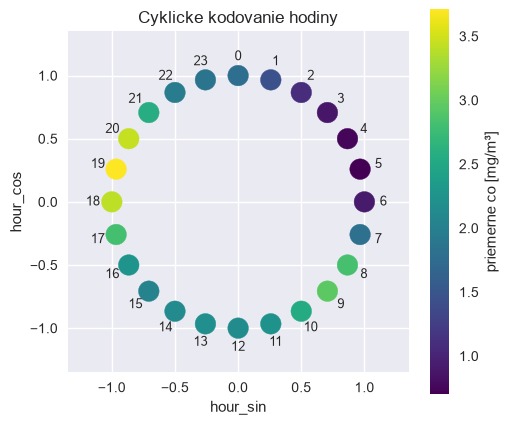

In [18]:
# hodiny na kruznici, farba = priemerna koncentracia co v danej hodine
po_hodinach = df_clean.groupby("hour")["co"].mean()
uhol = 2 * np.pi * po_hodinach.index / 24

fig, ax = plt.subplots(figsize=(5.5, 5))
sc = ax.scatter(np.sin(uhol), np.cos(uhol), c=po_hodinach.values, cmap="viridis", s=220, zorder=3)
for h, u in zip(po_hodinach.index, uhol):
    ax.annotate(str(h), (1.15 * np.sin(u), 1.15 * np.cos(u)), ha="center", va="center", fontsize=9)
plt.colorbar(sc, label="priemerne co [mg/m³]")
ax.set_xlabel("hour_sin"); ax.set_ylabel("hour_cos")
ax.set_title("Cyklicke kodovanie hodiny")
ax.set_aspect("equal")
ax.set_xlim(-1.35, 1.35); ax.set_ylim(-1.35, 1.35)
plt.show()

Na kružnici ležia susedné hodiny vedľa seba aj cez polnoc (23 → 0). Farba zároveň ukazuje, prečo je čas pre model dôležitý: koncentrácia `co` má dve **dopravné špičky**, rannú okolo 8.–9. hodiny a večernú okolo 18.–20. hodiny, a minimum v noci okolo 4.–5. hodiny.

### 1.5 Rozdelenie dát (train / test) a normalizácia

Validačnú množinu v tomto zadaní nepotrebujeme, delíme len na **trénovaciu (80 %) a testovaciu (20 %)**. Ide o regresiu, takže `stratify` nepoužívame. Potom v každej množine oddelíme vstupy `X` od výstupu `y = co`.

Vstupy štandardizujeme (`StandardScaler`, z-score), aby mali rovnakú mierku: merania majú hodnoty v stovkách až tisícoch, teplota v desiatkach a one-hot stĺpce 0/1. Pre SVM je to nevyhnutné, lebo pracuje so vzdialenosťami medzi bodmi. Scaler nastavíme **len na trénovacej množine** (inak by do trénovania unikla informácia z testu). Výstup `co` nenormalizujeme.

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. rozdelenie na trenovaciu a testovaciu mnozinu
train_df, test_df = train_test_split(df_enc, test_size=0.2, random_state=42)

# 2. rozdelenie na vstupy X a vystup y
X_train, y_train = train_df.drop(columns="co"), train_df["co"]
X_test,  y_test  = test_df.drop(columns="co"),  test_df["co"]
X = X_train.columns   # zoznam vstupnych priznakov

# 3. normalizacia vstupov (scaler nastaveny len na traine), vystup ostava v mg/m3
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),      columns=X, index=X_test.index)

print("train:", X_train_s.shape, " test:", X_test_s.shape)
print("vstupne priznaky:", list(X))

train: (5837, 17)  test: (1460, 17)
vstupne priznaky: ['sensor_co', 'sensor_nmhc', 'sensor_nox', 'sensor_no2', 'sensor_o3', 'temperature', 'humidity', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'weekday_sin', 'weekday_cos', 'season_autumn', 'season_spring', 'season_summer', 'season_winter']


In [20]:
# kontrola: po skalovani ma train priemer 0 a smerodajnu odchylku 1, test priblizne tiez
pd.DataFrame({
    "train priemer": X_train_s.mean(), "train std": X_train_s.std(),
    "test priemer": X_test_s.mean(), "test std": X_test_s.std(),
}).round(3)

,train priemer,train std,test priemer,test std
sensor_co,-0.0,1.0,0.032,1.032
sensor_nmhc,-0.0,1.0,0.020,1.006
sensor_nox,-0.0,1.0,-0.004,0.995
sensor_no2,0.0,1.0,0.024,0.988
sensor_o3,-0.0,1.0,0.022,1.031
temperature,0.0,1.0,-0.005,0.974
humidity,-0.0,1.0,-0.004,0.987
hour_sin,-0.0,1.0,0.022,0.996
hour_cos,0.0,1.0,-0.027,1.005
month_sin,-0.0,1.0,0.013,0.996


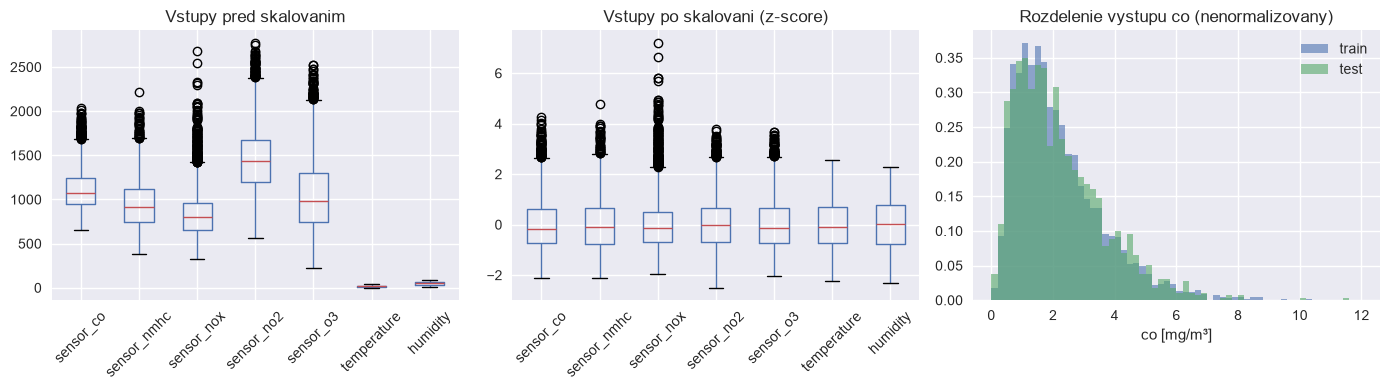

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

X_train[merania].boxplot(ax=axes[0], rot=45)
axes[0].set_title("Vstupy pred skalovanim")

X_train_s[merania].boxplot(ax=axes[1], rot=45)
axes[1].set_title("Vstupy po skalovani (z-score)")

kos = [i / 5 for i in range(61)]   # co je merane s krokom 0,1 -> kose po 0,2, aby histogram nebol zubaty
axes[2].hist(y_train, bins=kos, density=True, alpha=0.6, label="train")
axes[2].hist(y_test, bins=kos, density=True, alpha=0.6, label="test")
axes[2].set_title("Rozdelenie vystupu co (nenormalizovany)")
axes[2].set_xlabel("co [mg/m³]")
axes[2].legend()

plt.tight_layout()
plt.show()

**Výsledok:** trénovacia množina má **5 837** riadkov, testovacia **1 460**, vstupov je **17** (5 senzorov, teplota, vlhkosť, 6 cyklických stĺpcov času a 4 one-hot stĺpce ročného obdobia). Po škálovaní má trénovacia množina priemer 0 a smerodajnú odchýlku 1; testovacia je veľmi blízko (rozdiely do 0,04), čo potvrdzuje, že obe množiny pochádzajú z rovnakého rozdelenia. Rozdelenie výstupu `co` je v oboch množinách rovnaké: väčšina hodnôt je medzi 0,5 a 4 mg/m³ s dlhým chvostom vysokých koncentrácií. Výstup zostáva v pôvodných jednotkách (mg/m³), takže MSE a rezíduá budú priamo interpretovateľné.

## Časť 2: Modely

Všetky modely hodnotíme rovnako: **MSE**, **RMSE** (odmocnina z MSE, je v rovnakých jednotkách ako `co`, teda mg/m³) a **R²** na trénovacej aj testovacej množine. R² = 1 znamená dokonalú predikciu, R² = 0 znamená, že model nie je lepší než predpovedať vždy priemer, a R² môže byť aj záporné.

Stromové modely (strom aj ensemble) trénujeme na **neškálovaných** vstupoch: strom porovnáva hodnotu príznaku s prahom, takže škálovanie na jeho výsledok nemá vplyv, ale prahy v pôvodných jednotkách (napr. `sensor_nmhc <= 1 050`) sa dajú čítať. SVM trénujeme na škálovaných vstupoch, lebo pracuje so vzdialenosťami medzi bodmi.

In [22]:
from sklearn.metrics import mean_squared_error, r2_score

def vyhodnot(model, X_tr, X_te, nazov):
    """vrati slovnik metrik na traine a teste (+ predikcie na dalsie pouzitie)"""
    p_tr, p_te = model.predict(X_tr), model.predict(X_te)
    mse_tr, mse_te = mean_squared_error(y_train, p_tr), mean_squared_error(y_test, p_te)
    return {
        "model": nazov,
        "MSE train": round(mse_tr, 4), "MSE test": round(mse_te, 4),
        "RMSE train": round(mse_tr ** 0.5, 4), "RMSE test": round(mse_te ** 0.5, 4),
        "R2 train": round(r2_score(y_train, p_tr), 4), "R2 test": round(r2_score(y_test, p_te), 4),
    }

vysledky = {}      # metriky kazdeho modelu
predikcie = {}     # (pred_train, pred_test) pre grafy rezidualov

def zapis(model, X_tr, X_te, nazov):
    vysledky[nazov] = vyhodnot(model, X_tr, X_te, nazov)
    predikcie[nazov] = (model.predict(X_tr), model.predict(X_te))
    return pd.DataFrame([vysledky[nazov]]).set_index("model")

### 2.1 Rozhodovací strom

Najprv strom **bez obmedzenia** (predvolené nastavenie `DecisionTreeRegressor`): rastie, kým v každom liste nezostane jeden riadok.

In [23]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

strom_plny = DecisionTreeRegressor(random_state=42).fit(X_train, y_train)
print("hlbka:", strom_plny.get_depth(), " pocet listov:", strom_plny.get_n_leaves())
zapis(strom_plny, X_train, X_test, "Strom (bez obmedzenia)")

hlbka: 27  pocet listov: 4082


,MSE train,MSE test,RMSE train,RMSE test,R2 train,R2 test
model,,,,,,
Strom (bez obmedzenia),0.0,0.2416,0.0,0.4915,1.0,0.8839


Trénovacia chyba je nulová, strom si trénovacie dáta zapamätal (každý list = jeden riadok). Na teste je výrazne horší, ide o **pretrénovanie**. Obmedzíme rast stromu: skúsime maximálnu hĺbku a minimálny počet riadkov v liste.

In [24]:
riadky = []
for d in [3, 4, 5, 6, 8, 10, 12, None]:
    m = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_train, y_train)
    r = vyhodnot(m, X_train, X_test, f"max_depth={d}")
    r["listov"] = m.get_n_leaves()
    riadky.append(r)
for msl in [5, 10, 20, 50]:
    m = DecisionTreeRegressor(min_samples_leaf=msl, random_state=42).fit(X_train, y_train)
    r = vyhodnot(m, X_train, X_test, f"min_samples_leaf={msl}")
    r["listov"] = m.get_n_leaves()
    riadky.append(r)

tab_strom = pd.DataFrame(riadky).set_index("model")[["listov", "RMSE train", "RMSE test", "R2 train", "R2 test"]]
tab_strom

,listov,RMSE train,RMSE test,R2 train,R2 test
model,,,,,
max_depth=3,8,0.5590,0.5468,0.8490,0.8563
max_depth=4,16,0.4985,0.5034,0.8799,0.8782
max_depth=5,32,0.4530,0.4593,0.9009,0.8986
max_depth=6,63,0.4178,0.4476,0.9157,0.9037
max_depth=8,232,0.3426,0.4496,0.9433,0.9029
max_depth=10,680,0.2597,0.4593,0.9674,0.8986
max_depth=12,1517,0.1750,0.4892,0.9852,0.8850
max_depth=None,4082,0.0000,0.4915,1.0000,0.8839
min_samples_leaf=5,921,0.2605,0.4619,0.9672,0.8975


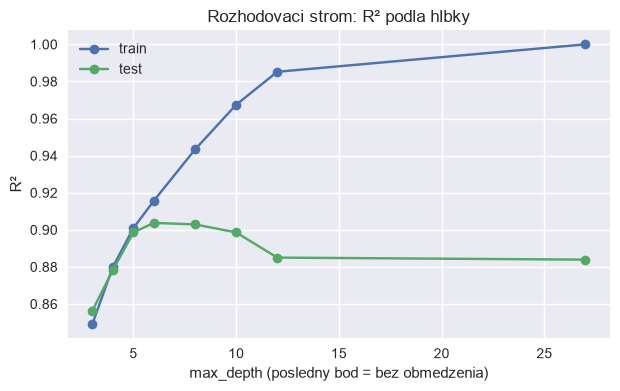

In [25]:
fig, ax = plt.subplots(figsize=(7, 4))
hlbky = tab_strom.index[tab_strom.index.str.startswith("max_depth")]
x = [int(h.split("=")[1]) if h != "max_depth=None" else strom_plny.get_depth() for h in hlbky]
ax.plot(x, tab_strom.loc[hlbky, "R2 train"], "o-", label="train")
ax.plot(x, tab_strom.loc[hlbky, "R2 test"], "o-", label="test")
ax.set_xlabel("max_depth (posledny bod = bez obmedzenia)")
ax.set_ylabel("R²")
ax.set_title("Rozhodovaci strom: R² podla hlbky")
ax.legend()
plt.show()

In [26]:
# vybrany strom: min_samples_leaf=20 (najlepsie R2 na teste, najmensi rozdiel train - test)
strom = DecisionTreeRegressor(min_samples_leaf=20, random_state=42).fit(X_train, y_train)
print("hlbka:", strom.get_depth(), " pocet listov:", strom.get_n_leaves())
zapis(strom, X_train, X_test, "Rozhodovaci strom")

hlbka: 13  pocet listov: 231


,MSE train,MSE test,RMSE train,RMSE test,R2 train,R2 test
model,,,,,,
Rozhodovaci strom,0.1459,0.1878,0.3819,0.4334,0.9295,0.9098


**Vizualizácia stromu.** Vybraný strom má desiatky listov a na obrázku by sa nedal čítať, preto pre vizualizáciu natrénujeme **menší strom s hĺbkou 3** (8 listov). Má horšie výsledky, ale dá sa z neho vyčítať, ako strom rozhoduje.

In [27]:
strom_maly = DecisionTreeRegressor(max_depth=3, random_state=42).fit(X_train, y_train)
zapis(strom_maly, X_train, X_test, "Strom (hlbka 3, na vizualizaciu)")

,MSE train,MSE test,RMSE train,RMSE test,R2 train,R2 test
model,,,,,,
"Strom (hlbka 3, na vizualizaciu)",0.3125,0.299,0.559,0.5468,0.849,0.8563


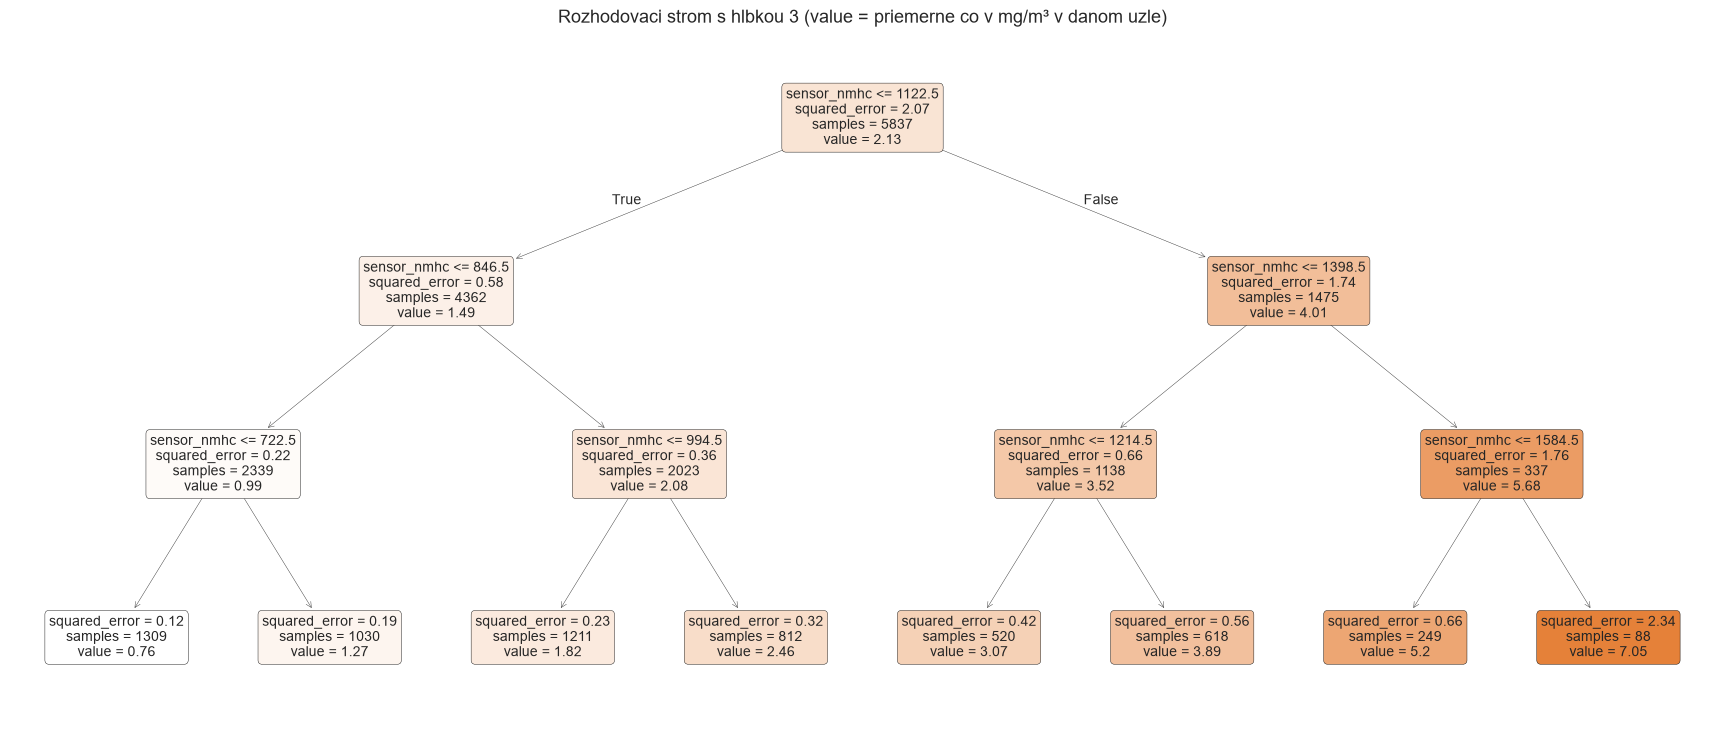

In [28]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(strom_maly, feature_names=list(X), filled=True, rounded=True, fontsize=10, precision=2, ax=ax)
ax.set_title("Rozhodovaci strom s hlbkou 3 (value = priemerne co v mg/m³ v danom uzle)", fontsize=13)
plt.show()

**Analýza stromu.** Malý strom sa vo **všetkých siedmich uzloch** pýta na ten istý príznak, `sensor_nmhc`: ide o najinformatívnejší vstup a strom hĺbky 3 iným príznakom ani nedá priestor. Koreň delí dáta prahom 1 122,5: pod ním je priemerné `co` 1,49 mg/m³ (4 362 riadkov), nad ním 4,01 mg/m³. Ďalšie delenia zjemňujú odhad: list úplne vľavo (`sensor_nmhc` ≤ 722,5) predpovedá 0,76 mg/m³, list úplne vpravo (> 1 584,5) 7,05 mg/m³. Strom teda funguje ako **schodovitá aproximácia** rastúcej závislosti `co` od `sensor_nmhc`; každý list vracia priemer svojich riadkov. Najväčšiu chybu má pravý krajný list (`squared_error` 2,34): len 88 riadkov s veľkým rozptylom, práve tam sú špičky znečistenia a 8 listov na ne nestačí.

**Výber hĺbky.** Strom bez obmedzenia má 4 082 listov (takmer jeden na riadok), trénovacie R² = 1,000 a testovacie 0,884: učebnicové pretrénovanie. S rastúcou hĺbkou trénovacie R² monotónne rastie, testovacie sa zastaví na ~0,90 pri hĺbke 6–8 a potom klesá. Najlepšie dopadlo obmedzenie `min_samples_leaf=20` (list musí mať aspoň 20 riadkov): **R² test 0,910**, RMSE 0,433 mg/m³, 231 listov, rozdiel train − test len 0,02. Tento strom používame ďalej.

### 2.2 Ensemble model: Random Forest

Ako súborový model volíme **náhodný les** (`RandomForestRegressor`): 300 stromov, ktoré sa od seba líšia dvoma zdrojmi náhody:
- každý strom sa učí na inom **náhodnom výbere riadkov s opakovaním** (bootstrap),
- v každom uzle vyberá otázku len z **náhodnej podmnožiny príznakov**: `max_features="sqrt"`, teda √17 ≈ 4 zo 17 príznakov. Bez tohto nastavenia (predvolené `max_features=1.0` pre regresiu) by každý strom v každom uzle videl všetky príznaky a takmer všetky stromy by začínali rovnakou otázkou, takže by si boli veľmi podobné.

Výsledok je **priemer** predikcií všetkých stromov. Jednotlivé stromy rastú bez obmedzenia a sú pretrénované, ale každý inak, a ich priemer sa pretrénuje oveľa menej než jeden strom.

In [29]:
from sklearn.ensemble import RandomForestRegressor

les = RandomForestRegressor(n_estimators=300, max_features="sqrt", random_state=42, n_jobs=-1).fit(X_train, y_train)
zapis(les, X_train, X_test, "Random Forest")

,MSE train,MSE test,RMSE train,RMSE test,R2 train,R2 test
model,,,,,,
Random Forest,0.0187,0.1243,0.1366,0.3526,0.991,0.9403


**Dôležitosť príznakov.** Random Forest meria, o koľko každý príznak znížil chybu (MSE) vo všetkých rozdeleniach všetkých stromov. Hodnoty sú normalizované tak, aby dávali súčet 1.

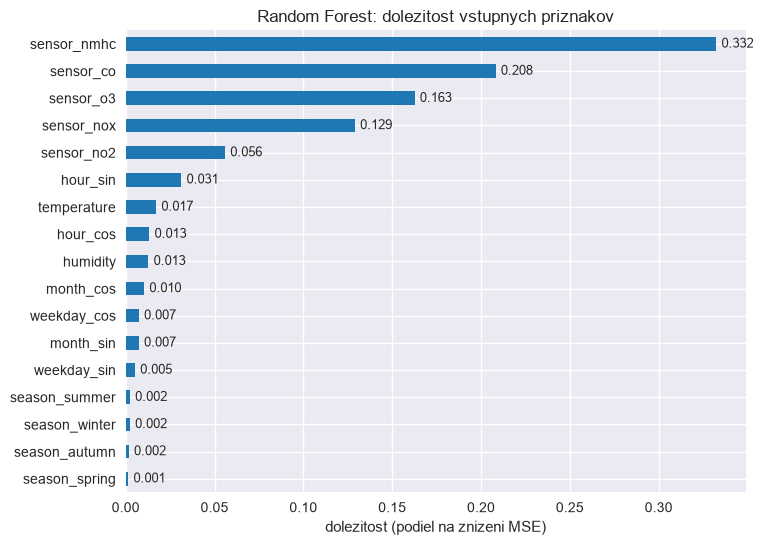

sucet dolezitosti 3 najdolezitejsich priznakov: 0.703


In [30]:
dolezitost = pd.Series(les.feature_importances_, index=X).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
dolezitost.plot.barh(ax=ax, color="tab:blue")
for i, v in enumerate(dolezitost.values):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("dolezitost (podiel na znizeni MSE)")
ax.set_title("Random Forest: dolezitost vstupnych priznakov")
plt.show()

print("sucet dolezitosti 3 najdolezitejsich priznakov:", round(dolezitost.sort_values(ascending=False).head(3).sum(), 3))

**Výsledok.** Random Forest dosahuje na teste **R² = 0,940**, RMSE 0,353 mg/m³, výrazne lepšie než jeden strom (0,910). Trénovacie R² 0,991 je vysoké, lebo jednotlivé stromy v lese rastú bez obmedzenia a priemer 300 pretrénovaných stromov si trénovacie dáta stále z veľkej časti „pamätá“; na teste sa to však nepremieta do straty presnosti, rozdiel train − test 0,05 je daň za priemerovanie neorezaných stromov, nie skutočné pretrénovanie.

**Dôležitosť príznakov.** Najdôležitejšie sú **senzory**: `sensor_nmhc` (33 %), `sensor_co` (21 %), `sensor_o3` (16 %), `sensor_nox` (13 %) a `sensor_no2` (6 %), spolu 89 % dôležitosti. Nasleduje čas (`hour_sin` 3,1 %, `hour_cos` 1,3 %) a počasie (`temperature` 1,7 %, `humidity` 1,3 %). Mesiac a deň v týždni majú pod 1 % a one-hot stĺpce `season` sú prakticky nulové (spolu 0,8 %): informáciu o ročnom období už nesú `month_sin`/`month_cos` a teplota. Zaujímavé je, že `sensor_co`, senzor nominálne zameraný na CO, je až druhý: senzor na nemetánové uhľovodíky koreluje s referenčným CO silnejšie (r = 0,92 vs. 0,88), pravdepodobne preto, že oba plyny majú rovnaký zdroj (doprava).

**Prečo je dôležitosť rozdelená medzi viac senzorov.** Senzory spolu silno korelujú (r 0,8 až 0,9), nesú teda podobnú informáciu. Vďaka `max_features="sqrt"` strom v každom uzle vidí len 4 náhodné príznaky; keď medzi nimi `sensor_nmhc` nie je, použije iný senzor a ten získa časť dôležitosti. Pri `max_features=1.0` (všetky príznaky v každom uzle) by takmer všetky stromy začínali otázkou na `sensor_nmhc` a ten by dostal 87 % dôležitosti, ostatné senzory len 1 až 2 %. Dôležitosť teda neopisuje len dáta, ale aj to, ako ich model používa: korelované príznaky sa o ňu delia. Tri najdôležitejšie príznaky spolu dávajú 70 %, na 95 % ich treba deväť, čo využijeme v časti 4.

### 2.3 SVM

`SVR` (Support Vector Regression) hľadá funkciu, okolo ktorej je pásmo šírky `epsilon`: body vo vnútri pásma sa netrestajú, body mimo neho sú **podporné vektory** a platí sa za ne pokuta úmerná **C**. Hyperparametre ako na cvičení: **druh jadra** (linear, rbf, poly), **C** (ako draho model platí za chyby: väčšie C = tesnejšie prispôsobenie trénovacím dátam, menšie C = hladšia funkcia) a **gamma** (šírka RBF funkcie: čím väčšia gamma, tým kratší dosah má jedna vzorka a tým zakrivenejšia je funkcia). `epsilon = 0.1` zodpovedá rozlíšeniu merania `co`. Používame **škálované** vstupy, lebo RBF jadro počíta vzdialenosti medzi bodmi.

In [31]:
from sklearn.svm import SVR

# vplyv C (RBF jadro, gamma=scale) a porovnanie druhov jadra na vsetkych 17 priznakoch
riadky = []
for C in [1, 3, 10, 30]:
    m = SVR(kernel="rbf", C=C, epsilon=0.1).fit(X_train_s, y_train)
    riadky.append(vyhodnot(m, X_train_s, X_test_s, f"SVR rbf, C={C}"))
for nazov, m in [("SVR linear, C=10", SVR(kernel="linear", C=10, epsilon=0.1)),
                 ("SVR poly (stupen 2), C=10", SVR(kernel="poly", degree=2, C=10, epsilon=0.1))]:
    riadky.append(vyhodnot(m.fit(X_train_s, y_train), X_train_s, X_test_s, nazov))

tab_C = pd.DataFrame(riadky).set_index("model")[["RMSE train", "RMSE test", "R2 train", "R2 test"]]
tab_C

,RMSE train,RMSE test,R2 train,R2 test
model,,,,
"SVR rbf, C=1",0.3424,0.3328,0.9434,0.9468
"SVR rbf, C=3",0.3096,0.3098,0.9537,0.9539
"SVR rbf, C=10",0.2735,0.2979,0.9639,0.9573
"SVR rbf, C=30",0.2335,0.2926,0.9737,0.9589
"SVR linear, C=10",0.4843,0.4423,0.8867,0.9060
"SVR poly (stupen 2), C=10",0.8144,0.7658,0.6795,0.7182


In [32]:
# vplyv gamma (RBF jadro, C=10); "scale" = 1 / (pocet priznakov * rozptyl dat) = 1/17 pri skalovanych datach
riadky = []
for g in [0.01, 0.03, "scale", 0.1, 0.3]:
    m = SVR(kernel="rbf", C=10, gamma=g, epsilon=0.1).fit(X_train_s, y_train)
    riadky.append(vyhodnot(m, X_train_s, X_test_s, f"SVR rbf, C=10, gamma={g}"))
gamma_scale = 1 / (X_train_s.shape[1] * X_train_s.values.var())
print("gamma = scale je tu", round(gamma_scale, 4))
tab_gamma = pd.DataFrame(riadky).set_index("model")[["RMSE train", "RMSE test", "R2 train", "R2 test"]]
tab_gamma

gamma = scale je tu 0.0588


,RMSE train,RMSE test,R2 train,R2 test
model,,,,
"SVR rbf, C=10, gamma=0.01",0.3793,0.3469,0.9305,0.9422
"SVR rbf, C=10, gamma=0.03",0.3203,0.3087,0.9505,0.9542
"SVR rbf, C=10, gamma=scale",0.2735,0.2979,0.9639,0.9573
"SVR rbf, C=10, gamma=0.1",0.2181,0.2928,0.9770,0.9588
"SVR rbf, C=10, gamma=0.3",0.1070,0.3421,0.9945,0.9438


In [33]:
# vybrane nastavenie: RBF, C=10, gamma=scale (C=30 aj gamma=0.1 zlepsuju test len o tisiciny, ale zvacsuju rozdiel train - test)
svm = SVR(kernel="rbf", C=10, epsilon=0.1).fit(X_train_s, y_train)
zapis(svm, X_train_s, X_test_s, "SVM (SVR rbf)")

,MSE train,MSE test,RMSE train,RMSE test,R2 train,R2 test
model,,,,,,
SVM (SVR rbf),0.0748,0.0888,0.2735,0.2979,0.9639,0.9573


Ako vyzerá naučená funkcia SVR, si ukážeme na **jednom príznaku** `sensor_nmhc` (najdôležitejší z lesa), kde sa dá nakresliť: body sú trénovacie riadky, červená čiara je predikcia SVR s rovnakým nastavením (RBF, C = 10).

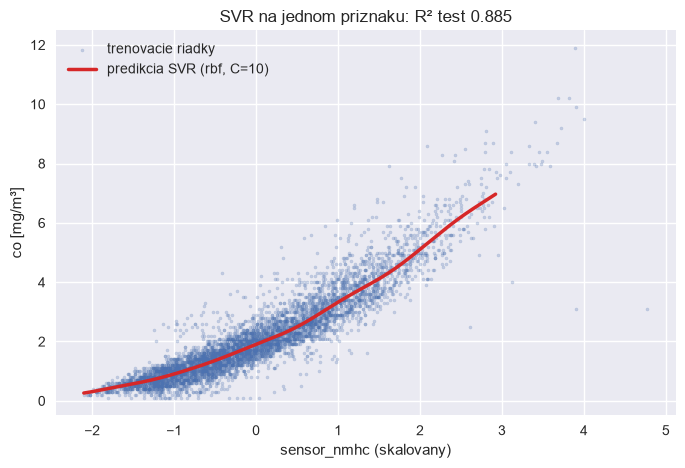

In [34]:
f = "sensor_nmhc"
svm_1d = SVR(kernel="rbf", C=10, epsilon=0.1).fit(X_train_s[[f]], y_train)
mriezka = pd.DataFrame({f: np.linspace(X_train_s[f].min(), X_train_s[f].quantile(0.995), 400)})   # ciaru kreslime tam, kde su data

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_train_s[f], y_train, s=5, alpha=0.25, label="trenovacie riadky")
ax.plot(mriezka[f], svm_1d.predict(mriezka), color="tab:red", lw=2.5, label="predikcia SVR (rbf, C=10)")
ax.set_xlabel(f"{f} (skalovany)"); ax.set_ylabel("co [mg/m³]")
ax.set_title(f"SVR na jednom priznaku: R² test {r2_score(y_test, svm_1d.predict(X_test_s[[f]])):.3f}")
ax.legend()
plt.show()

Čiara sleduje tvar dát: pri nízkom signáli rastie pomaly, pri vysokom čoraz rýchlejšie (senzor saturuje, rovnaká zmena signálu znamená väčšiu zmenu CO). Priamka by tento tvar neopísala, preto lineárne jadro dopadlo horšie. Samotný `sensor_nmhc` dá R² okolo 0,88, zvyšok dodajú ostatné príznaky.

**Výsledok.** SVR s RBF jadrom je **najlepší model**: na teste **R² = 0,957**, RMSE 0,298 mg/m³, a zároveň má najmenší rozdiel medzi trénovaním a testom (0,007), takže nie je pretrénovaný. Rast C od 1 po 30 zlepšuje test z 0,947 na 0,959, ale od C = 10 je zisk už len v tisícinách, zatiaľ čo trénovacie R² rastie ďalej (0,964 → 0,974) a čas trénovania sa zdvojnásobuje; volíme preto **C = 10**. Pri gamma: malá gamma (0,01) model vyhladí a test klesne na 0,942, veľká gamma (0,3) vyženie trénovacie R² na 0,995, ale test padne na 0,944, teda pretrénovanie. Predvolené `gamma = "scale"` (tu 0,059) je blízko optima, gamma = 0,1 pridá na teste len tisícinu za cenu väčšieho rozdielu train − test, ostávame preto pri predvolenej hodnote. Lineárne jadro dosiahlo len 0,906, horšie než samotný rozhodovací strom: vzťah medzi senzormi a koncentráciou CO je nelineárny (senzory saturujú pri vysokých koncentráciách) a RBF jadro ho zachytí, priamka nie. Polynomiálne jadro 2. stupňa je ešte horšie (0,718).

### 2.4 Porovnanie modelov a rezíduá

**Rezíduum** = skutočná hodnota − predpovedaná hodnota. Pri dobrom modeli sú rezíduá malé, sústredené okolo nuly a **bez vzoru**: nemali by závisieť od predpovedanej hodnoty. Kreslíme rezíduá oproti predikcii a ich rozdelenie, v oboch grafoch trénovaciu (modrá) a testovaciu (červená) množinu spolu, aby bolo vidieť aj rozdiel medzi nimi.

In [35]:
porovnanie = pd.DataFrame([vysledky[k] for k in ["Rozhodovaci strom", "Random Forest", "SVM (SVR rbf)"]]).set_index("model")
porovnanie["R2 rozdiel (train - test)"] = (porovnanie["R2 train"] - porovnanie["R2 test"]).round(4)
porovnanie

,MSE train,MSE test,RMSE train,RMSE test,R2 train,R2 test,R2 rozdiel (train - test)
model,,,,,,,
Rozhodovaci strom,0.1459,0.1878,0.3819,0.4334,0.9295,0.9098,0.0197
Random Forest,0.0187,0.1243,0.1366,0.3526,0.9910,0.9403,0.0507
SVM (SVR rbf),0.0748,0.0888,0.2735,0.2979,0.9639,0.9573,0.0066


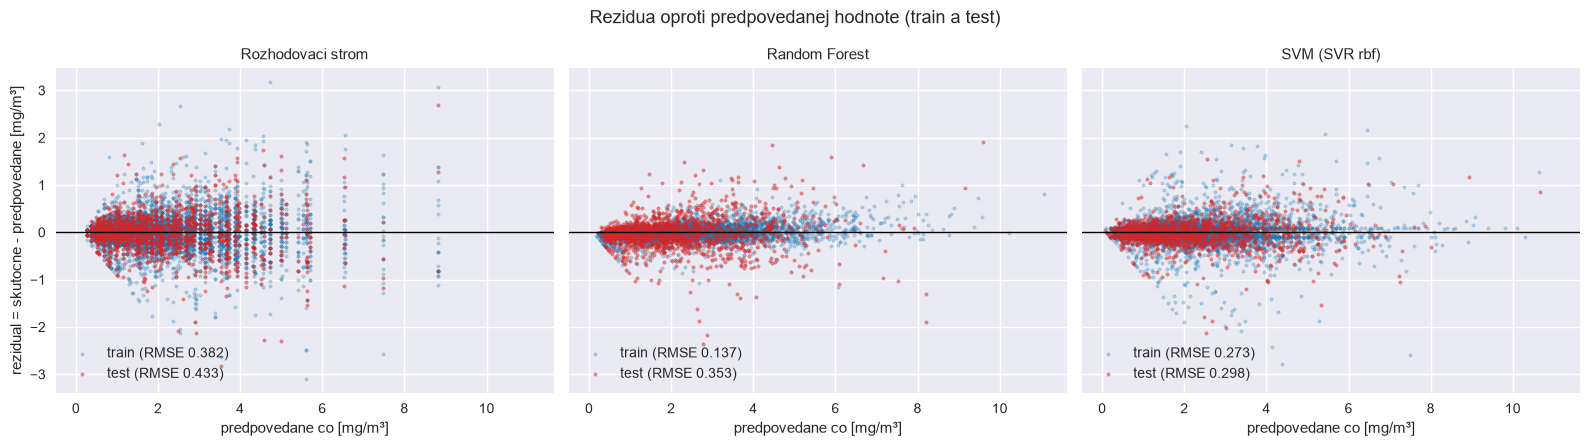

In [36]:
modely = ["Rozhodovaci strom", "Random Forest", "SVM (SVR rbf)"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for ax, nazov in zip(axes, modely):
    p_tr, p_te = predikcie[nazov]
    rez_tr, rez_te = y_train - p_tr, y_test - p_te
    ax.scatter(p_tr, rez_tr, s=6, alpha=0.3, color="tab:blue", label=f"train (RMSE {rez_tr.pow(2).mean() ** 0.5:.3f})")
    ax.scatter(p_te, rez_te, s=6, alpha=0.5, color="tab:red", label=f"test (RMSE {rez_te.pow(2).mean() ** 0.5:.3f})")
    ax.axhline(0, color="black", lw=1)
    ax.set_title(nazov, fontsize=11)
    ax.set_xlabel("predpovedane co [mg/m³]")
    ax.legend(loc="lower left")
axes[0].set_ylabel("rezidual = skutocne - predpovedane [mg/m³]")
fig.suptitle("Rezidua oproti predpovedanej hodnote (train a test)", fontsize=13)
plt.tight_layout()
plt.show()

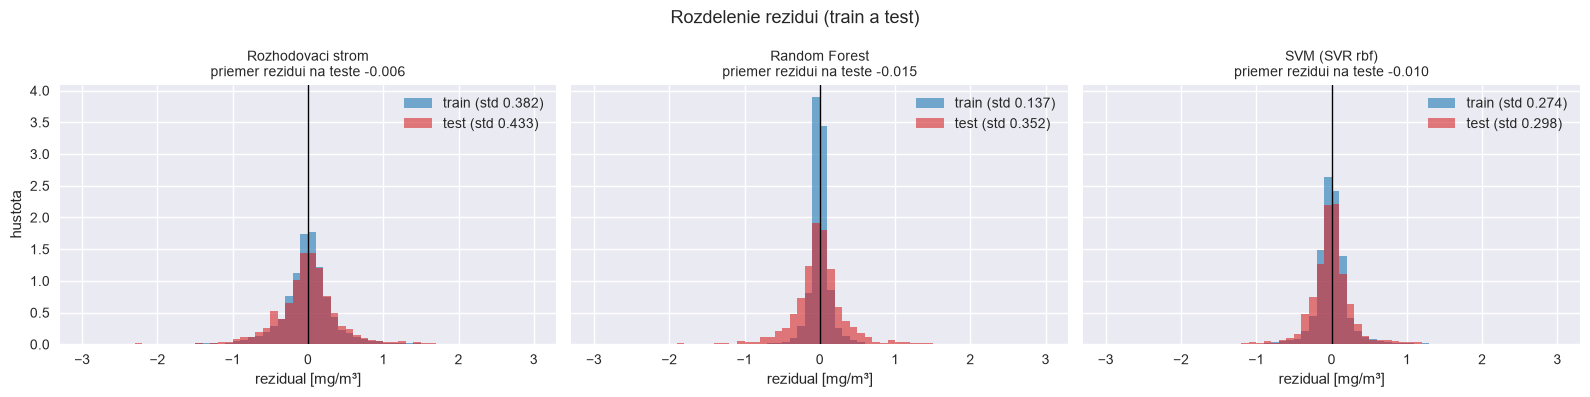

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
kose = np.arange(-3, 3.01, 0.1)
for ax, nazov in zip(axes, modely):
    rez_tr, rez_te = y_train - predikcie[nazov][0], y_test - predikcie[nazov][1]
    ax.hist(rez_tr, bins=kose, density=True, alpha=0.6, color="tab:blue", label=f"train (std {rez_tr.std():.3f})")
    ax.hist(rez_te, bins=kose, density=True, alpha=0.6, color="tab:red", label=f"test (std {rez_te.std():.3f})")
    ax.axvline(0, color="black", lw=1)
    ax.set_title(f"{nazov}\npriemer rezidui na teste {rez_te.mean():.3f}", fontsize=10)
    ax.set_xlabel("rezidual [mg/m³]")
    ax.legend()
axes[0].set_ylabel("hustota")
fig.suptitle("Rozdelenie rezidui (train a test)", fontsize=13)

plt.tight_layout()
plt.show()

In [38]:
# kde modely chybuju najviac: priemerna absolutna chyba na teste podla velkosti skutocneho co
pasma = pd.cut(y_test, bins=[0, 1, 2, 3, 5, 12], labels=["0-1", "1-2", "2-3", "3-5", "5+"])
pd.DataFrame({nazov: (y_test - predikcie[nazov][1]).abs().groupby(pasma, observed=True).mean().round(3)
              for nazov in modely}).rename_axis("skutocne co [mg/m³]").assign(**{"pocet riadkov": pasma.value_counts().sort_index()})

,Rozhodovaci strom,Random Forest,SVM (SVR rbf),pocet riadkov
skutocne co [mg/m³],,,,
0-1,0.201,0.170,0.138,378
1-2,0.224,0.169,0.140,439
2-3,0.328,0.238,0.194,297
3-5,0.421,0.328,0.285,286
5+,0.666,0.585,0.444,60


**Porovnanie modelov.** Všetky tri modely majú kladné R² a prekračujú požadovaných 0,7; poradie na teste je **SVM (0,957) > Random Forest (0,940) > rozhodovací strom (0,910)**. RMSE najlepšieho modelu 0,30 mg/m³ znamená, že typická chyba predikcie je asi 14 % priemernej koncentrácie (2,13 mg/m³).

**Rezíduá.** Vo všetkých modeloch sú rezíduá sústredené okolo nuly (priemer na teste −0,015 až −0,006, modely teda systematicky nenadhodnocujú ani nepodhodnocujú) a rozdelenia sú symetrické. Rozdiely sú v rozptyle: std rezíduí na teste 0,43 (strom), 0,35 (les), 0,30 (SVM). Rozhodovací strom má v trénovacích (modrých) bodoch typické **zvislé pásy**: strom vracia len 231 rôznych hodnôt (po jednej na list), takže predikcie sú diskrétne. Random Forest má modré body nápadne bližšie k nule než červené (trénovací histogram je výrazne užší), to je ten rozdiel train − test z tabuľky. SVM má rezíduá najužšie a modré a červené body sa takmer prekrývajú, rozdiel medzi trénovaním a testom takmer žiadny.

**Spoločný vzor.** U všetkých modelov sa rozptyl rezíduí **zväčšuje s rastúcou predikciou**: pri `co` do 2 mg/m³ je priemerná absolútna chyba 0,14 až 0,22 mg/m³, pri `co` nad 5 mg/m³ už 0,44 až 0,67 mg/m³. Dôvody sú dva: vysokých koncentrácií je v dátach málo (60 testovacích riadkov nad 5 mg/m³ oproti 378 pod 1 mg/m³), takže modely majú z čoho sa učiť hlavne bežné hodnoty, a senzory pri vysokých koncentráciách saturujú, teda rovnaká zmena signálu zodpovedá väčšej zmene skutočného CO. Práve tu sa najviac prejaví výhoda SVM, ktorého chyba na špičkách (0,44) je o tretinu nižšia než chyba stromu (0,67).

**Prečo SVM vyhral nad lesom.** Závislosť `co` od senzorov je plynulá. Stromy a les skladajú predikciu zo schodov (aj priemer 300 stromov je stále schodovitý, najmä tam, kde je málo dát), kým SVM s RBF jadrom vytvorí hladkú funkciu, ktorá takúto závislosť opisuje prirodzenejšie.

Ako **najúspešnejší model** pre časť 4 berieme **SVM (SVR rbf, C = 10)**.

## Časť 3: Redukcia dimenzie

Dáta majú 17 vstupných rozmerov, človek vidí tri. Porovnáme dva spôsoby, ako ich zobraziť v 3D: **vybrať tri pôvodné príznaky** a **zredukovať všetkých 17 na tri nové osi pomocou PCA**. V oboch grafoch body farbíme podľa výstupu `co`.

### 3.1 3D graf vybraných príznakov

Vyberáme príznaky **pred normalizáciou** (osi sú v pôvodných jednotkách), podľa korelácie s `co` a tak, aby sa graf dal interpretovať:
- `sensor_nmhc`: najsilnejšia kladná korelácia s `co` (r = 0,92) a najdôležitejší príznak v Random Foreste,
- `sensor_nox`: najsilnejšia **záporná** korelácia (r = −0,70), jediný senzor, ktorého signál s CO klesá,
- `hour`: časový príznak s najväčším vplyvom (r = 0,36), ukáže denný cyklus.

In [39]:
df_eda.corr(numeric_only=True)["co"].drop("co").sort_values().round(3).to_frame("korelacia s co").T

,sensor_nox,temperature,humidity,month,weekday,hour,sensor_no2,sensor_o3,sensor_co,sensor_nmhc
korelacia s co,-0.704,0.028,0.045,0.106,0.114,0.361,0.632,0.854,0.879,0.916


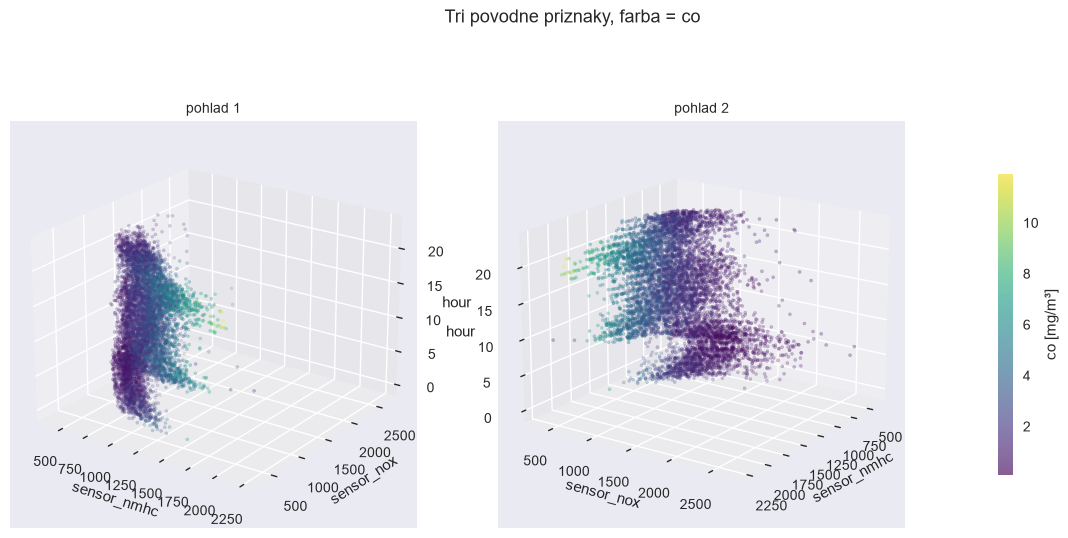

In [40]:
def graf3d(ax, x, y, z, farba, nazvy, elev, azim, title):
    sc = ax.scatter(x, y, z, c=farba, cmap="viridis", s=5, alpha=0.6)
    ax.set_xlabel(nazvy[0]); ax.set_ylabel(nazvy[1]); ax.set_zlabel(nazvy[2])
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(title, fontsize=10)
    return sc

osi = ["sensor_nmhc", "sensor_nox", "hour"]
fig = plt.figure(figsize=(15, 6.5))
for k, (elev, azim) in enumerate([(22, -55), (18, 35)]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    sc = graf3d(ax, df_eda[osi[0]], df_eda[osi[1]], df_eda[osi[2]], df_eda["co"], osi,
                elev, azim, f"pohlad {k + 1}")
fig.colorbar(sc, ax=fig.axes, shrink=0.6, pad=0.08, label="co [mg/m³]")
fig.suptitle("Tri povodne priznaky, farba = co", fontsize=13)
plt.show()

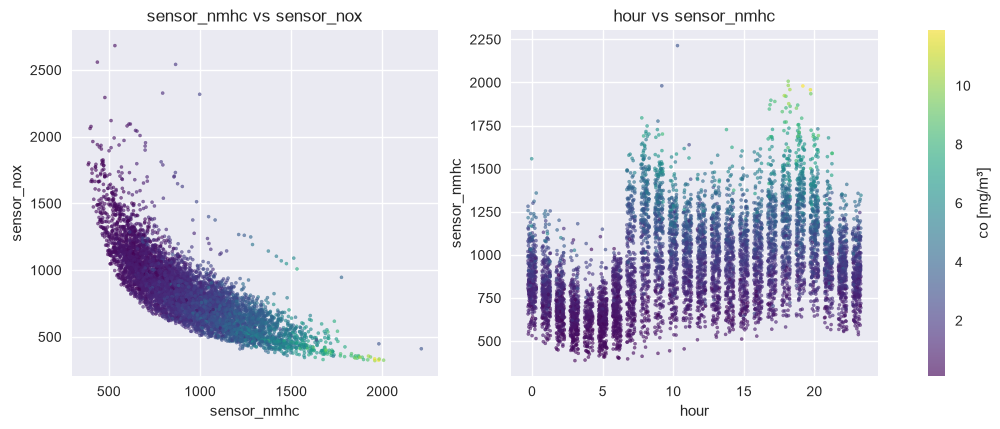

In [41]:
# doplnok k 3D grafu: ten isty vztah po dvojiciach (lahsie sa cita)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sc = axes[0].scatter(df_eda["sensor_nmhc"], df_eda["sensor_nox"], c=df_eda["co"], cmap="viridis", s=5, alpha=0.6)
axes[0].set_xlabel("sensor_nmhc"); axes[0].set_ylabel("sensor_nox"); axes[0].set_title("sensor_nmhc vs sensor_nox")
axes[1].scatter(df_eda["hour"] + np.random.uniform(-0.3, 0.3, len(df_eda)), df_eda["sensor_nmhc"],
                c=df_eda["co"], cmap="viridis", s=5, alpha=0.6)
axes[1].set_xlabel("hour"); axes[1].set_ylabel("sensor_nmhc"); axes[1].set_title("hour vs sensor_nmhc")
fig.colorbar(sc, ax=axes, label="co [mg/m³]")
plt.show()

**Čo z grafu vidno.** Body tvoria zakrivený „oblúk“: s rastúcim `sensor_nmhc` klesá `sensor_nox` a farba sa mení z fialovej (nízke `co`) na žltú (vysoké `co`). Závislosť je **hladká a monotónna**: vysoké CO sa vyskytuje len v rohu s vysokým `sensor_nmhc` a nízkym `sensor_nox`, nikde inde. Vzťah `sensor_nmhc` – `sensor_nox` je zjavne **nelineárny** (hyperbolický tvar), čo vysvetľuje, prečo lineárne SVM v časti 2 zaostalo za RBF jadrom.

Os `hour` pridáva **denný cyklus**: medzi 1. a 6. hodinou sú všetky body v úzkom fialovom páse (nízky `sensor_nmhc`, nízke CO, nočný pokoj), o 7.–8. hodine sa oblak náhle roztiahne nahor a najvyššie hodnoty CO (žlté body) sú sústredené v dvoch pásoch, okolo 8.–9. a 18.–20. hodiny, teda v rannej a večernej dopravnej špičke. Pri tých istých hodnotách senzora je farba v rôznych hodinách podobná: hodina teda sama o sebe CO neurčuje, ale určuje, **kedy** sa vysoké hodnoty senzorov vyskytujú. To sedí s dôležitosťou príznakov z Random Forestu, kde `hour_sin` a `hour_cos` dostali spolu len 4,4 %.

### 3.2 3D graf po redukcii dimenzie (PCA)

**PCA** (analýza hlavných komponentov) nájde nové osi: lineárne kombinácie pôvodných príznakov, zoradené podľa toho, koľko rozptylu dát vysvetľujú. Prvé tri komponenty sú najlepšia 3D projekcia v zmysle zachovaného rozptylu. PCA pracuje s rozptylom, preto ju spúšťame na **normalizovaných** vstupoch (inak by senzory s hodnotami v tisíckach prehlušili všetko ostatné) a **bez výstupu `co`**. Komponenty nastavíme na trénovacej množine a premietneme všetky riadky.

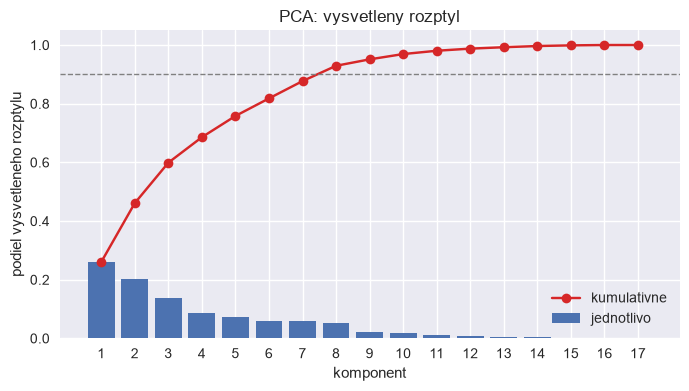

prve 3 komponenty vysvetluju 59.9% rozptylu


In [42]:
from sklearn.decomposition import PCA

pca = PCA().fit(X_train_s)
var = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, len(var) + 1), var, label="jednotlivo")
ax.plot(range(1, len(var) + 1), np.cumsum(var), "o-", color="tab:red", label="kumulativne")
ax.axhline(0.9, color="gray", ls="--", lw=1)
ax.set_xlabel("komponent"); ax.set_ylabel("podiel vysvetleneho rozptylu")
ax.set_xticks(range(1, len(var) + 1))
ax.set_title("PCA: vysvetleny rozptyl")
ax.legend()
plt.show()

print("prve 3 komponenty vysvetluju", f"{var[:3].sum():.1%}", "rozptylu")

In [43]:
# z coho sa skladaju prve tri komponenty (vahy povodnych priznakov)
zatazenia = pd.DataFrame(pca.components_[:3].T, index=X, columns=["PC1", "PC2", "PC3"]).round(2)
zatazenia.style.background_gradient(cmap="RdBu_r", vmin=-0.6, vmax=0.6)

,PC1,PC2,PC3
sensor_co,0.410000,0.220000,0.130000
sensor_nmhc,0.450000,0.100000,0.040000
sensor_nox,-0.380000,-0.170000,0.020000
sensor_no2,0.410000,-0.150000,0.040000
sensor_o3,0.390000,0.240000,0.030000
temperature,0.210000,-0.440000,-0.070000
humidity,-0.050000,0.320000,-0.140000
hour_sin,-0.180000,0.030000,-0.080000
hour_cos,-0.110000,0.030000,-0.060000
month_sin,-0.120000,0.200000,0.560000


In [44]:
# premietnutie vsetkych riadkov (train aj test) do priestoru prvych 3 komponentov
X_all_s = pd.concat([X_train_s, X_test_s]).loc[df_enc.index]
y_all = df_enc["co"]
Z = pca.transform(X_all_s)[:, :3]

for i in range(3):
    print(f"korelacia PC{i + 1} s co: {np.corrcoef(Z[:, i], y_all)[0, 1]:6.3f}")

korelacia PC1 s co:  0.832
korelacia PC2 s co:  0.362
korelacia PC3 s co:  0.075


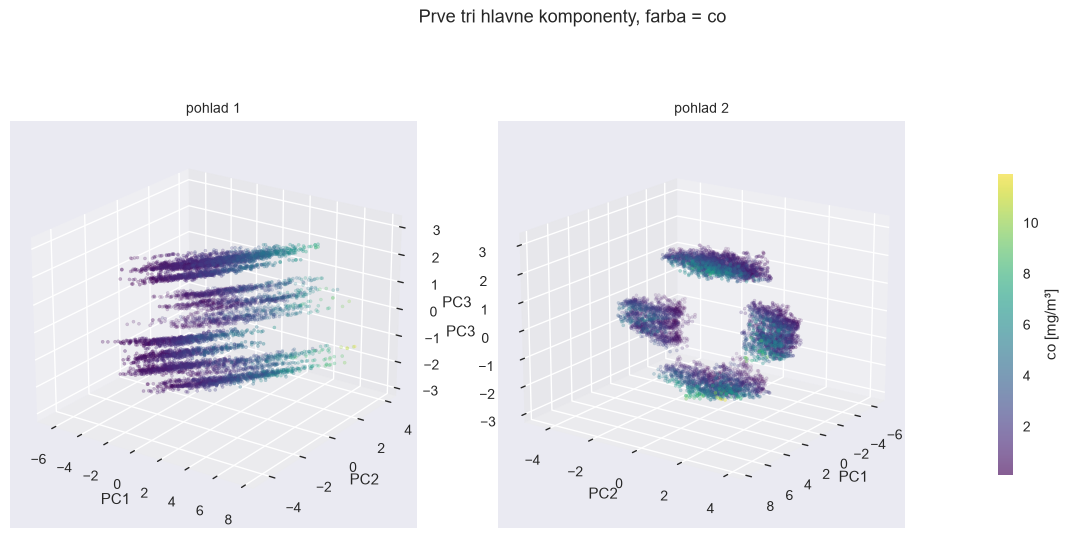

In [45]:
fig = plt.figure(figsize=(15, 6.5))
for k, (elev, azim) in enumerate([(22, -55), (18, 35)]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    sc = graf3d(ax, Z[:, 0], Z[:, 1], Z[:, 2], y_all, ["PC1", "PC2", "PC3"], elev, azim, f"pohlad {k + 1}")
fig.colorbar(sc, ax=fig.axes, shrink=0.6, pad=0.08, label="co [mg/m³]")
fig.suptitle("Prve tri hlavne komponenty, farba = co", fontsize=13)
plt.show()

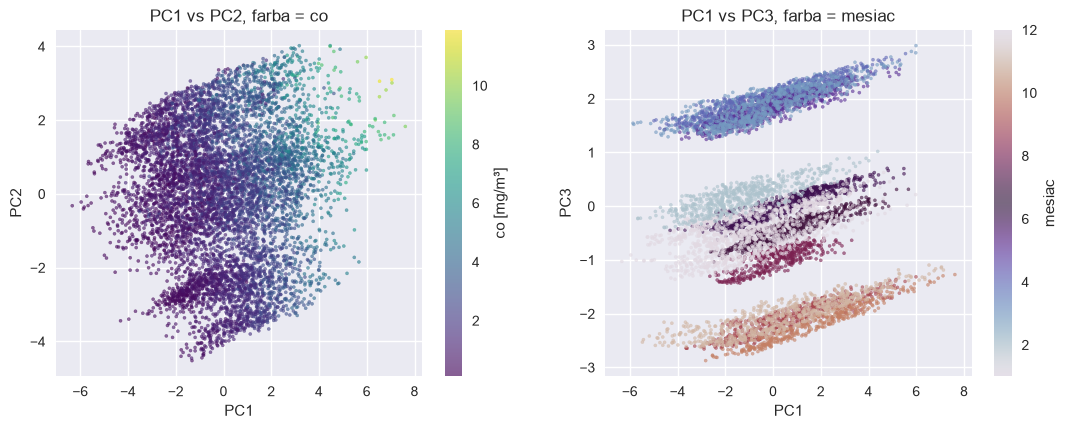

In [46]:
# PC3 je zlozena hlavne z month_sin a season: preto body v 3D grafe lezia vo vrstvach podla mesiaca
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sc = axes[0].scatter(Z[:, 0], Z[:, 1], c=y_all, cmap="viridis", s=5, alpha=0.6)
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].set_title("PC1 vs PC2, farba = co")
fig.colorbar(sc, ax=axes[0], label="co [mg/m³]")
sc2 = axes[1].scatter(Z[:, 0], Z[:, 2], c=df_eda["month"], cmap="twilight", s=5, alpha=0.6)
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC3"); axes[1].set_title("PC1 vs PC3, farba = mesiac")
fig.colorbar(sc2, ax=axes[1], label="mesiac")
plt.show()

**Čo PCA našla.** Prvé tri komponenty vysvetľujú len **60 %** rozptylu (26 + 20 + 14 %); na 90 % treba 8 komponentov. Dáta sa teda do troch rozmerov nezmestia bez straty, lebo 17 vstupov nesie viac než tri nezávislé zdroje variability. Z váh komponentov vidno, čo každá os znamená:
- **PC1** je „os znečistenia“: kladné váhy všetkých senzorov (`sensor_nmhc` 0,45, `sensor_co` 0,41, `sensor_no2` 0,41, `sensor_o3` 0,39) a záporná `sensor_nox` (−0,38). Koreluje s `co` na **0,83**, takže farba sa v grafe mení hlavne pozdĺž PC1.
- **PC2** je „os počasia a ročného obdobia“: záporná teplota (−0,44) a leto (−0,41), kladná vlhkosť (0,32), zima (0,35) a `month_cos` (0,45). Korelácia s `co` 0,36.
- **PC3** je skladá takmer výlučne z `month_sin` (0,56), `season_spring` (0,56) a `season_autumn` (−0,48), teda z **diskrétnych** príznakov. S `co` nekoreluje (0,08).

**Prečo body ležia vo vrstvách.** V 3D grafe nie je spojitý oblak, ale niekoľko rovnobežných „plátov“ pozdĺž PC3. Graf PC1 vs PC3 zafarbený podľa mesiaca to vysvetľuje: každá vrstva je jeden mesiac alebo ročné obdobie. One-hot a cyklické kódovanie času dávajú mesiacu len 12 možných hodnôt, a PCA túto diskrétnu štruktúru vyniesla na tretiu os. Tretia os teda zobrazuje kalendár, nie znečistenie.

### 3.3 Porovnanie grafov

**Graf z pôvodných príznakov je na analýzu CO lepší.** Osi majú fyzikálny význam (odozva senzora, hodina), takže sa dá priamo povedať „vysoké CO = vysoký NMHC signál, nízky NOx signál, dopravná špička“ a vidno aj nelineárny tvar závislosti. Nevýhodou je, že ukazuje len 3 zo 17 príznakov; vybrali sme ich však podľa korelácie a dôležitosti, takže ide o tie, ktoré o CO vypovedajú najviac.

**PCA graf** zachováva informáciu zo všetkých 17 príznakov, ale ukazuje len 60 % ich rozptylu a osi nemajú priamy význam, treba ich čítať z tabuľky váh. Prvá komponenta zhŕňa všetkých päť senzorov do jednej „osi znečistenia“ (farebný gradient pozdĺž PC1 je rovnako čistý ako pozdĺž `sensor_nmhc`), čo je užitočné zhrnutie. Druhá a tretia komponenta však vysvetľujú **ročné obdobie a mesiac**, nie CO: PCA maximalizuje rozptyl vstupov bez ohľadu na výstup, a sezónne príznaky majú po normalizácii veľký rozptyl, hoci s CO súvisia slabo. Výsledkom sú vrstvy podľa mesiaca, ktoré na pochopenie CO nepomáhajú.

Zhrnutie: ručný výber príznakov využíva znalosť cieľa (vyberáme podľa vzťahu k `co`), PCA cieľ nepozná a časť troch rozmerov minie na variabilitu, ktorá s CO nesúvisí. Pre tieto dáta, kde jeden príznak (`sensor_nmhc`) vysvetľuje väčšinu CO, je priama projekcia na pôvodné príznaky čitateľnejšia.

## Časť 4: Výber podmnožiny príznakov

Najúspešnejší model z časti 2 je **SVM (SVR rbf, C = 10)**. Natrénujeme ho znova na troch zmenšených množinách príznakov, vybraných tromi rôznymi spôsobmi, a porovnáme s pôvodným trénovaním na všetkých 17 príznakoch. Vo všetkých prípadoch používame rovnaké rozdelenie train/test a rovnaké škálovanie ako doteraz (vyberáme len stĺpce zo škálovaných matíc).

In [47]:
def svm_na_podmnozine(X_tr, X_te, nazov):
    """natrenuje SVM s rovnakym nastavenim ako v casti 2 na danej podmnozine stlpcov / komponentov"""
    m = SVR(kernel="rbf", C=10, epsilon=0.1).fit(X_tr, y_train)
    p_tr, p_te = m.predict(X_tr), m.predict(X_te)
    vysledky[nazov] = vyhodnot(m, X_tr, X_te, nazov)
    vysledky[nazov]["pocet vstupov"] = X_tr.shape[1]
    predikcie[nazov] = (p_tr, p_te)
    return pd.DataFrame([vysledky[nazov]]).set_index("model")

# povodne trenovanie na vsetkych 17 priznakoch uz mame v `vysledky["SVM (SVR rbf)"]`
vysledky["SVM (SVR rbf)"]["pocet vstupov"] = X_train_s.shape[1]

### 4.1 Podľa korelačnej matice

Korelačnú maticu počítame na **trénovacej množine** (výber príznakov je súčasť trénovania, test do neho nesmie zasahovať). Hľadáme dve veci: príznaky, ktoré s výstupom `co` korelujú slabo (model im nemá čo odčítať), a dvojice príznakov, ktoré silne korelujú medzi sebou (nesú duplicitnú informáciu).

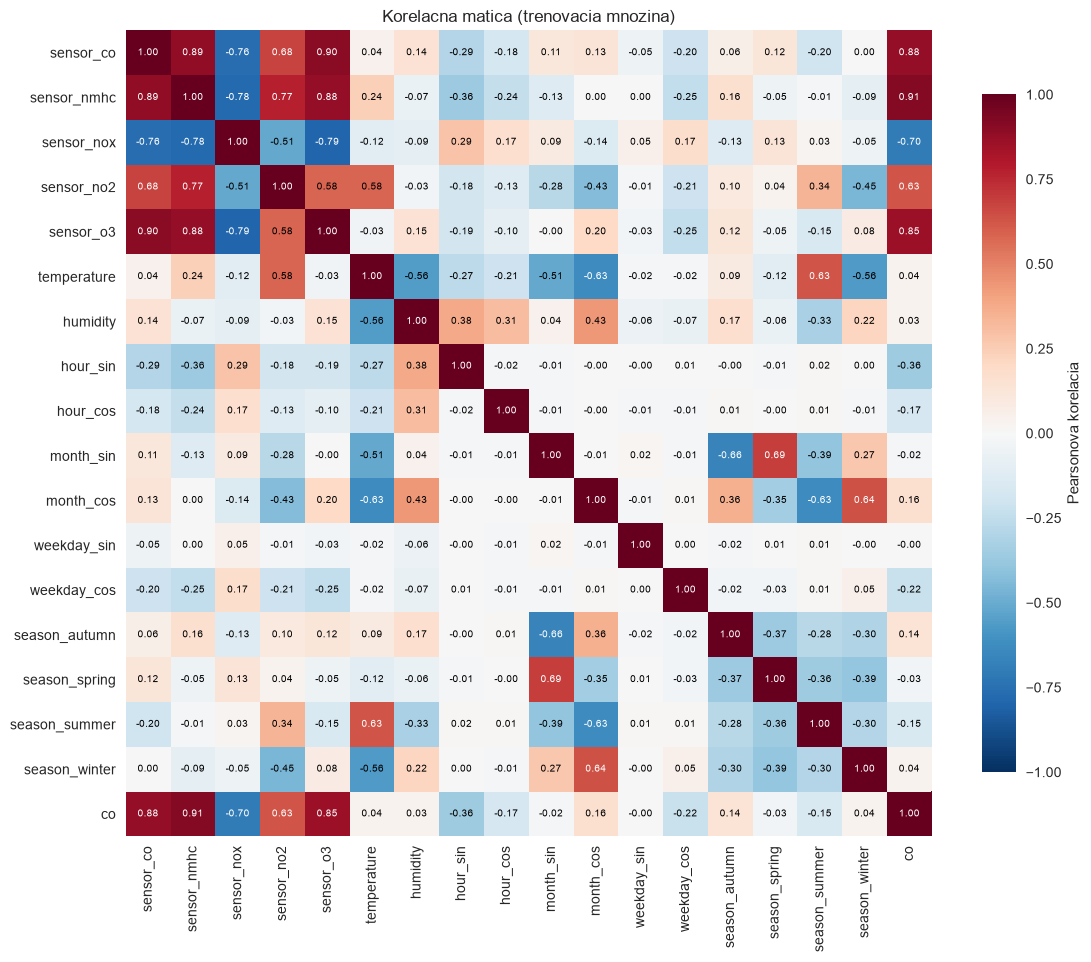

In [48]:
korelacie = pd.concat([X_train_s, y_train], axis=1).corr()

fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(korelacie, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(korelacie))); ax.set_xticklabels(korelacie.columns, rotation=90)
ax.set_yticks(range(len(korelacie))); ax.set_yticklabels(korelacie.columns)
for i in range(len(korelacie)):
    for j in range(len(korelacie)):
        v = korelacie.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else "black")
ax.grid(False)
plt.colorbar(im, shrink=0.8, label="Pearsonova korelacia")
ax.set_title("Korelacna matica (trenovacia mnozina)")
plt.show()

In [49]:
kor_co = korelacie["co"].drop("co")
kor_co.abs().sort_values(ascending=False).round(3).to_frame("|korelacia s co|").T

,sensor_nmhc,sensor_co,sensor_o3,sensor_nox,sensor_no2,hour_sin,weekday_cos,hour_cos,month_cos,season_summer,season_autumn,season_winter,temperature,humidity,season_spring,month_sin,weekday_sin
|korelacia s co|,0.914,0.878,0.852,0.699,0.631,0.359,0.219,0.167,0.162,0.149,0.137,0.038,0.038,0.034,0.027,0.02,0.003


In [50]:
# dvojice vstupnych priznakov s |r| > 0.7: nesu z velkej casti rovnaku informaciu
k = korelacie.drop(columns="co", index="co")
dvojice = [(a, b, round(k.loc[a, b], 2)) for i, a in enumerate(k.index) for b in k.columns[i + 1:] if abs(k.loc[a, b]) > 0.7]
pd.DataFrame(dvojice, columns=["priznak 1", "priznak 2", "r"])

,priznak 1,priznak 2,r
0,sensor_co,sensor_nmhc,0.89
1,sensor_co,sensor_nox,-0.76
2,sensor_co,sensor_o3,0.90
3,sensor_nmhc,sensor_nox,-0.78
4,sensor_nmhc,sensor_no2,0.77
5,sensor_nmhc,sensor_o3,0.88
6,sensor_nox,sensor_o3,-0.79


In [51]:
# ako zavisi vysledok od prahu |korelacia s co|
riadky = []
for prah in [0.1, 0.2, 0.3, 0.5]:
    vyber = kor_co[kor_co.abs() >= prah].index.tolist()
    r = vyhodnot(SVR(kernel="rbf", C=10, epsilon=0.1).fit(X_train_s[vyber], y_train), X_train_s[vyber], X_test_s[vyber], f"|r| >= {prah}")
    r["pocet vstupov"] = len(vyber)
    riadky.append(r)
pd.DataFrame(riadky).set_index("model")[["pocet vstupov", "RMSE train", "RMSE test", "R2 train", "R2 test"]]

,pocet vstupov,RMSE train,RMSE test,R2 train,R2 test
model,,,,,
|r| >= 0.1,11,0.3421,0.3418,0.9435,0.9439
|r| >= 0.2,7,0.3836,0.3742,0.9289,0.9327
|r| >= 0.3,6,0.3977,0.3943,0.9236,0.9253
|r| >= 0.5,5,0.4144,0.4036,0.9170,0.9217


In [52]:
# zvoleny prah 0.2: ostanu priznaky, ktore maju s co aspon slaby vztah
prah = 0.2
vyber_kor = kor_co[kor_co.abs() >= prah].index.tolist()
print(f"vybrane priznaky ({len(vyber_kor)}):", vyber_kor)
print("vyradene:", [c for c in X if c not in vyber_kor])
svm_na_podmnozine(X_train_s[vyber_kor], X_test_s[vyber_kor], "SVM, korelacia")

vybrane priznaky (7): ['sensor_co', 'sensor_nmhc', 'sensor_nox', 'sensor_no2', 'sensor_o3', 'hour_sin', 'weekday_cos']
vyradene: ['temperature', 'humidity', 'hour_cos', 'month_sin', 'month_cos', 'weekday_sin', 'season_autumn', 'season_spring', 'season_summer', 'season_winter']


,MSE train,MSE test,RMSE train,RMSE test,R2 train,R2 test,pocet vstupov
model,,,,,,,
"SVM, korelacia",0.1471,0.14,0.3836,0.3742,0.9289,0.9327,7


**Čo matica ukazuje.** S výstupom `co` silno korelujú len senzory (|r| 0,63 až 0,91) a slabo `hour_sin` (0,36) a `weekday_cos` (0,22). Všetko ostatné má |r| pod 0,17: teplota a vlhkosť majú s CO lineárny vzťah takmer nulový (0,04 a 0,03) a sezónne príznaky tiež. Medzi vstupmi sú dve skupiny duplicity: päť senzorov koreluje navzájom na |r| 0,51 až 0,90 (všetky reagujú na tú istú dopravnú záťaž), a one-hot stĺpce `season` korelujú s `month_sin`/`month_cos` (|r| až 0,69), lebo ročné obdobie je z mesiaca odvodené, nesú teda tú istú informáciu dvakrát.

**Výber.** Prah |r| ≥ 0,2 ponechá **7 príznakov**: päť senzorov, `hour_sin` a `weekday_cos`. Vyradené sú teplota, vlhkosť, mesiac a všetky štyri stĺpce `season`. SVM na nich dosahuje **R² test 0,933** (RMSE 0,374) oproti 0,957 na všetkých 17. Pokles o 0,024 ukazuje, že vyradené príznaky síce s CO lineárne nekorelujú, ale SVM s RBF jadrom z nich niečo vyťaží **nelineárne**: teplota a vlhkosť napríklad ovplyvňujú citlivosť senzorov, takže ten istý signál znamená pri inej teplote inú koncentráciu. Korelačná matica meria len lineárny vzťah, a práve to je jej slabina pri výbere príznakov pre nelineárny model. Tabuľka prahov to potvrdzuje: čím prísnejší prah, tým horší výsledok, a pri |r| ≥ 0,1 (11 príznakov) je R² 0,944.

### 4.2 Podľa dôležitosti príznakov z ensemble modelu

Použijeme dôležitosti z Random Forestu z časti 2. Zoradíme príznaky od najdôležitejšieho a berieme ich, kým ich **kumulatívna dôležitosť** nedosiahne 95 %. Zvyšné príznaky (mesiac, deň v týždni, ročné obdobie) prispievajú každý najviac 1 %, spolu menej než 5 %.

In [53]:
dol = dolezitost.sort_values(ascending=False)
kumul = dol.cumsum()
tab_dol = pd.DataFrame({"dolezitost": dol.round(3), "kumulativne": kumul.round(3)})
tab_dol

,dolezitost,kumulativne
sensor_nmhc,0.332,0.332
sensor_co,0.208,0.541
sensor_o3,0.163,0.703
sensor_nox,0.129,0.832
sensor_no2,0.056,0.888
hour_sin,0.031,0.919
temperature,0.017,0.936
hour_cos,0.013,0.949
humidity,0.013,0.962
month_cos,0.010,0.973


In [54]:
# ako zavisi vysledok od poctu najdolezitejsich priznakov
riadky = []
for n in [1, 2, 3, 5, 7, 10]:
    vyber = dol.index[:n].tolist()
    r = vyhodnot(SVR(kernel="rbf", C=10, epsilon=0.1).fit(X_train_s[vyber], y_train), X_train_s[vyber], X_test_s[vyber], f"top {n}")
    r["pocet vstupov"] = n
    riadky.append(r)
pd.DataFrame(riadky).set_index("model")[["pocet vstupov", "RMSE train", "RMSE test", "R2 train", "R2 test"]]

,pocet vstupov,RMSE train,RMSE test,R2 train,R2 test
model,,,,,
top 1,1,0.5207,0.4883,0.8690,0.8854
top 2,2,0.4751,0.4427,0.8909,0.9058
top 3,3,0.4637,0.4456,0.8961,0.9046
top 5,5,0.4144,0.4036,0.9170,0.9217
top 7,7,0.3737,0.3707,0.9325,0.9339
top 10,10,0.3418,0.3463,0.9436,0.9424


In [55]:
vyber_dol = kumul[kumul <= 0.95].index.tolist()
if len(vyber_dol) < len(kumul):
    vyber_dol.append(kumul.index[len(vyber_dol)])   # prvy priznak, ktorym prekrocime 95 %
print(f"vybrane priznaky ({len(vyber_dol)}):", vyber_dol)
print("ich kumulativna dolezitost:", round(dol[vyber_dol].sum(), 3))
svm_na_podmnozine(X_train_s[vyber_dol], X_test_s[vyber_dol], "SVM, dolezitost RF")

vybrane priznaky (9): ['sensor_nmhc', 'sensor_co', 'sensor_o3', 'sensor_nox', 'sensor_no2', 'hour_sin', 'temperature', 'hour_cos', 'humidity']
ich kumulativna dolezitost: 0.962


,MSE train,MSE test,RMSE train,RMSE test,R2 train,R2 test,pocet vstupov
model,,,,,,,
"SVM, dolezitost RF",0.1245,0.1237,0.3529,0.3516,0.9398,0.9406,9


**Výber.** Hranicu 95 % kumulatívnej dôležitosti prekročí **9 príznakov**: päť senzorov, `hour_sin`, `temperature`, `hour_cos` a `humidity` (spolu 96,2 %). Vyradené sú mesiac, deň v týždni a ročné obdobie. Oproti korelačnému výberu sa sem dostali **teplota a vlhkosť**, hoci s CO lineárne takmer nekorelujú (r 0,04 a 0,03), a naopak vypadol `weekday_cos`. Random Forest meria užitočnosť príznaku v stromoch, teda vrátane nelineárnych a kombinovaných efektov (napr. „vysoký signál senzora **a** nízka teplota“), preto teplotu a vlhkosť „vidí“ a korelácia nie.

**Výsledok.** SVM na 9 príznakoch dosahuje **R² test 0,941** (RMSE 0,352), **najviac z troch metód**. Tabuľka podľa počtu príznakov ukazuje, ako výsledok rastie: samotný `sensor_nmhc` dá 0,885, všetkých päť senzorov 0,922, s `hour_sin` a teplotou 0,934 a 10 príznakov 0,942. Zaujímavý je krok z dvoch na tri príznaky (0,906 → 0,905): tretí senzor `sensor_o3` nepridá nič, lebo s prvými dvoma koreluje na 0,88 až 0,90 a nesie tú istú informáciu. Výber podľa dôležitosti z iného modelu (lesa) funguje pre SVM dobre, lebo oba modely sú nelineárne a využívajú podobné vzťahy.

### 4.3 Podľa variancie pomocou PCA

Namiesto výberu pôvodných stĺpcov použijeme hlavné komponenty z časti 3. Nevyberáme počet komponentov, ale **podiel vysvetleného rozptylu**: `PCA(n_components=0.90)` si sám zoberie toľko komponentov, koľko treba na 90 % rozptylu trénovacích dát.

In [56]:
# ako zavisi vysledok od pozadovaneho podielu rozptylu
riadky = []
for podiel in [0.80, 0.90, 0.95, 0.99]:
    p = PCA(n_components=podiel).fit(X_train_s)
    r = vyhodnot(SVR(kernel="rbf", C=10, epsilon=0.1).fit(p.transform(X_train_s), y_train), p.transform(X_train_s), p.transform(X_test_s), f"variancia >= {podiel:.0%}")
    r["pocet vstupov"] = p.n_components_
    riadky.append(r)
pd.DataFrame(riadky).set_index("model")[["pocet vstupov", "RMSE train", "RMSE test", "R2 train", "R2 test"]]

,pocet vstupov,RMSE train,RMSE test,R2 train,R2 test
model,,,,,
variancia >= 80%,6,0.4293,0.4252,0.9110,0.9131
variancia >= 90%,8,0.3819,0.3991,0.9296,0.9235
variancia >= 95%,9,0.3540,0.3704,0.9395,0.9341
variancia >= 99%,13,0.2932,0.3088,0.9585,0.9542


In [57]:
pca90 = PCA(n_components=0.90).fit(X_train_s)
print("pocet komponentov na 90 % rozptylu:", pca90.n_components_,
      "| skutocne vysvetleny rozptyl:", f"{pca90.explained_variance_ratio_.sum():.1%}")
Z_train = pca90.transform(X_train_s)
Z_test = pca90.transform(X_test_s)
svm_na_podmnozine(Z_train, Z_test, "SVM, PCA 90 %")

pocet komponentov na 90 % rozptylu: 8 | skutocne vysvetleny rozptyl: 92.9%


,MSE train,MSE test,RMSE train,RMSE test,R2 train,R2 test,pocet vstupov
model,,,,,,,
"SVM, PCA 90 %",0.1458,0.1592,0.3819,0.3991,0.9296,0.9235,8


**Výber.** Na 90 % rozptylu treba **8 komponentov** (skutočne vysvetlia 92,9 %). SVM na nich dosahuje **R² test 0,924** (RMSE 0,399), teda najmenej z troch metód: horšie než korelačný výber (0,933, 7 vstupov) aj výber podľa dôležitosti (0,941, 9 vstupov). Tabuľka podľa podielu rozptylu ukazuje plynulý rast: 80 % → 0,913, 95 % → 0,934, 99 % → 0,954; až pri 13 komponentoch sa model priblíži pôvodnému výsledku.

**Prečo PCA nestačí 90 %.** PCA vyberá komponenty podľa rozptylu **vstupov**, nie podľa vzťahu k výstupu. V časti 3 sme videli, že druhá a tretia komponenta opisujú ročné obdobie a mesiac, ktoré s CO súvisia slabo, zatiaľ čo informácia o vplyve teploty na senzory môže byť rozložená v komponentoch s malým rozptylom, ktoré sa pri 90 % zahodia. Zahodených 7 % rozptylu teda nie je šum, ale časť signálu užitočného pre predikciu. Druhá nevýhoda je interpretovateľnosť: 8 komponentov je 8 lineárnych kombinácií všetkých 17 príznakov, takže oproti výberu pôvodných stĺpcov sa nič „nezjednoduší“, do modelu stále vstupujú všetky senzory.

### 4.4 Porovnanie

Štyri trénovania toho istého modelu: na všetkých 17 príznakoch a na troch zmenšených množinách.

In [58]:
varianty = ["SVM (SVR rbf)", "SVM, korelacia", "SVM, dolezitost RF", "SVM, PCA 90 %"]
porovnanie4 = pd.DataFrame([vysledky[k] for k in varianty]).set_index("model")
porovnanie4 = porovnanie4[["pocet vstupov", "MSE train", "MSE test", "RMSE train", "RMSE test", "R2 train", "R2 test"]]
porovnanie4["R2 rozdiel (train - test)"] = (porovnanie4["R2 train"] - porovnanie4["R2 test"]).round(4)
porovnanie4

,pocet vstupov,MSE train,MSE test,RMSE train,RMSE test,R2 train,R2 test,R2 rozdiel (train - test)
model,,,,,,,,
SVM (SVR rbf),17,0.0748,0.0888,0.2735,0.2979,0.9639,0.9573,0.0066
"SVM, korelacia",7,0.1471,0.1400,0.3836,0.3742,0.9289,0.9327,-0.0038
"SVM, dolezitost RF",9,0.1245,0.1237,0.3529,0.3516,0.9398,0.9406,-0.0008
"SVM, PCA 90 %",8,0.1458,0.1592,0.3819,0.3991,0.9296,0.9235,0.0061


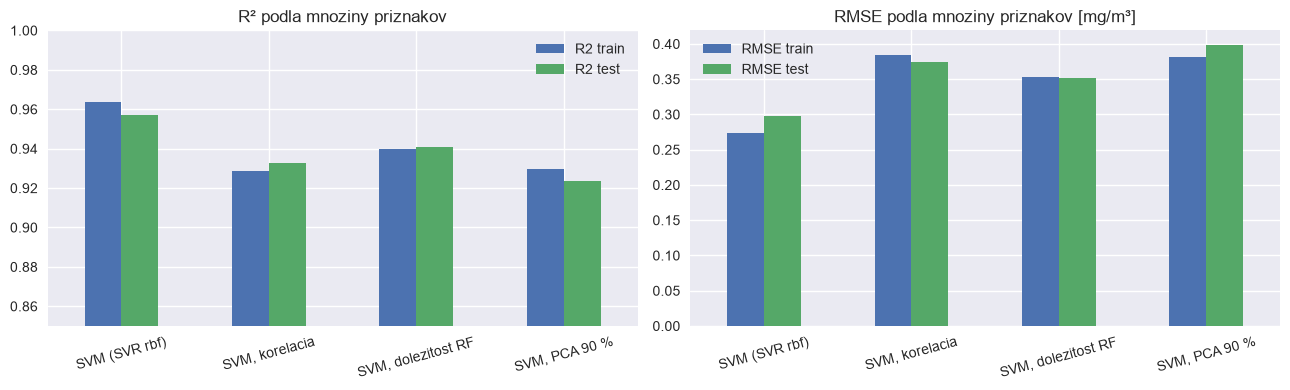

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
porovnanie4[["R2 train", "R2 test"]].plot.bar(ax=axes[0], rot=15)
axes[0].set_ylim(0.85, 1.0); axes[0].set_title("R² podla mnoziny priznakov"); axes[0].set_xlabel("")
porovnanie4[["RMSE train", "RMSE test"]].plot.bar(ax=axes[1], rot=15)
axes[1].set_title("RMSE podla mnoziny priznakov [mg/m³]"); axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

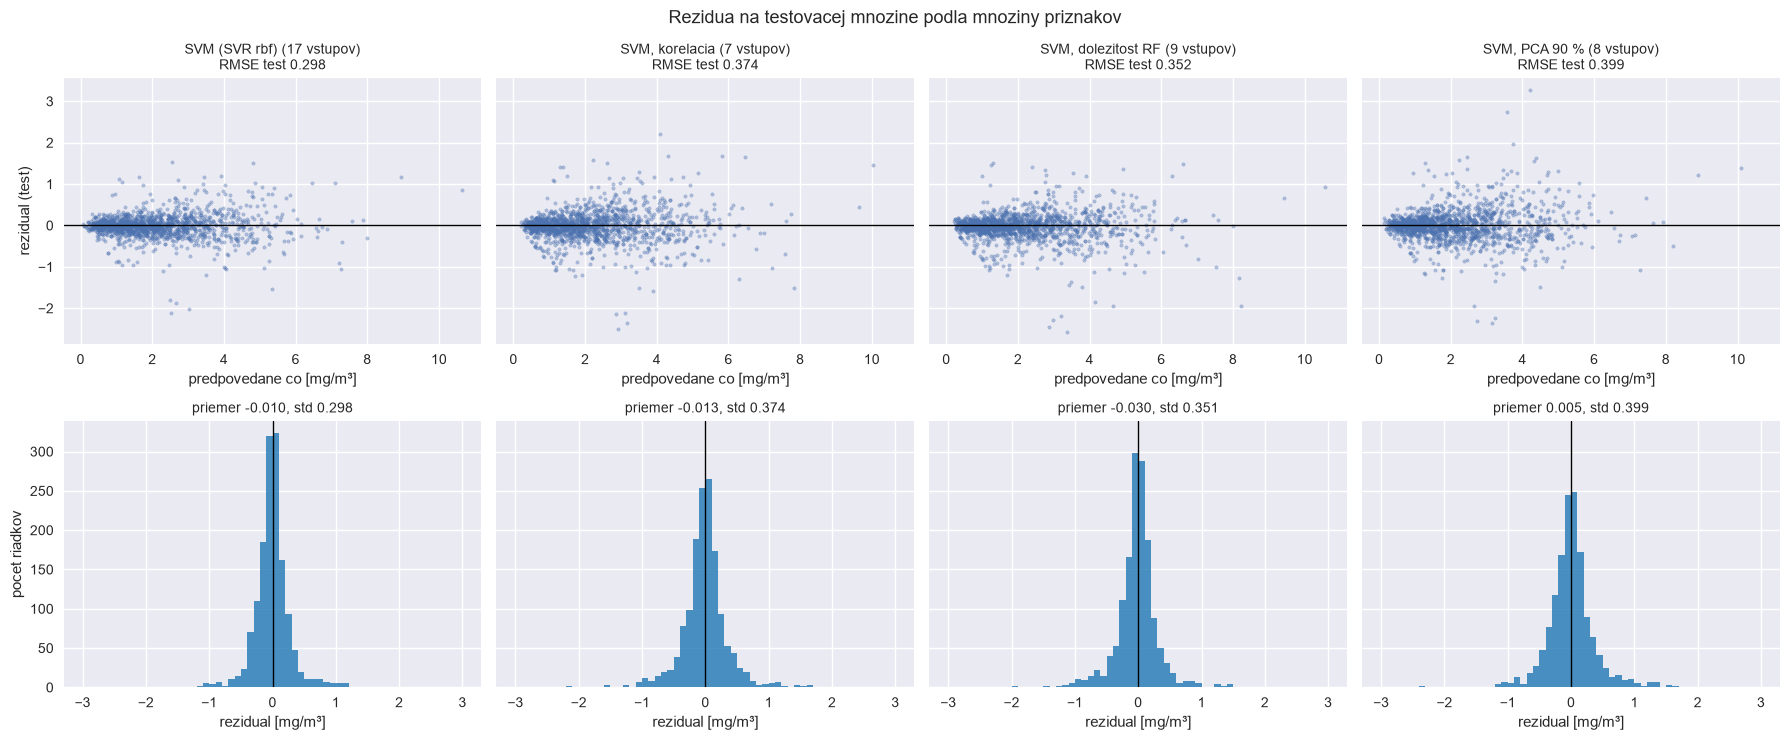

In [60]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5), sharex="row", sharey="row")
for j, nazov in enumerate(varianty):
    rez = y_test - predikcie[nazov][1]
    ax = axes[0, j]
    ax.scatter(predikcie[nazov][1], rez, s=6, alpha=0.4)
    ax.axhline(0, color="black", lw=1)
    ax.set_title(f"{nazov} ({vysledky[nazov]['pocet vstupov']} vstupov)\nRMSE test {rez.pow(2).mean() ** 0.5:.3f}", fontsize=10)
    ax.set_xlabel("predpovedane co [mg/m³]")
    ax = axes[1, j]
    ax.hist(rez, bins=np.arange(-3, 3.01, 0.1), color="tab:blue", alpha=0.8)
    ax.axvline(0, color="black", lw=1)
    ax.set_title(f"priemer {rez.mean():.3f}, std {rez.std():.3f}", fontsize=10)
    ax.set_xlabel("rezidual [mg/m³]")
axes[0, 0].set_ylabel("rezidual (test)")
axes[1, 0].set_ylabel("pocet riadkov")
fig.suptitle("Rezidua na testovacej mnozine podla mnoziny priznakov", fontsize=13)
plt.tight_layout()
plt.show()

In [61]:
# chyba podla velkosti skutocneho co: kde sa zmensena mnozina priznakov prejavi najviac
pd.DataFrame({nazov: (y_test - predikcie[nazov][1]).abs().groupby(pasma, observed=True).mean().round(3)
              for nazov in varianty}).rename_axis("skutocne co [mg/m³]")

,SVM (SVR rbf),"SVM, korelacia","SVM, dolezitost RF","SVM, PCA 90 %"
skutocne co [mg/m³],,,,
0-1,0.138,0.194,0.185,0.176
1-2,0.140,0.170,0.152,0.188
2-3,0.194,0.257,0.243,0.271
3-5,0.285,0.351,0.302,0.381
5+,0.444,0.519,0.462,0.665


**Porovnanie.** Všetky tri zmenšené množiny dávajú stále veľmi dobrý model (R² 0,92 až 0,94), ale **žiadna neprekonala pôvodných 17 príznakov** (0,957). Poradie: dôležitosť RF (9 vstupov, 0,941) > korelácia (7 vstupov, 0,933) > PCA 90 % (8 vstupov, 0,924). Rozdiel train − test je vo všetkých prípadoch do 0,007, zmenšenie množiny teda nebolo potrebné proti pretrénovaniu, model nebol pretrénovaný ani predtým.

**Rezíduá.** Tvar rezíduí sa zmenšením množiny nezmenil: všetky štyri varianty majú priemer blízko nuly (−0,03 až +0,01) a symetrický histogram, ide teda stále o nestranné modely. Rozdiel je v šírke: std rezíduí stúpne z 0,30 na 0,35 až 0,40 mg/m³. Tabuľka podľa pásiem `co` ukazuje, kde sa chýbajúce príznaky prejavia najviac: pri nízkych koncentráciách (0–2 mg/m³) rastie chyba o 0,01 až 0,06, pri špičkách nad 5 mg/m³ o 0,02 až 0,22. Výber podľa dôležitosti si na špičkách drží takmer pôvodnú presnosť (0,462 oproti 0,444), najviac stráca PCA (0,665), lebo informácia o extrémoch leží v komponentoch s malým rozptylom.

**Záver časti.** Dáta majú jeden dominantný príznak (`sensor_nmhc` sám dá R² 0,885), ale zvyšných 16 pridáva spolu ďalších 7 percentuálnych bodov a každý z nich prispieva málo, takže akýkoľvek výber niečo stratí. Ak by bol dôvod množinu zmenšiť, najlepší pomer dáva **výber podľa dôležitosti z Random Forestu**: 9 vstupov a strata len 0,017 R². Vyradené stĺpce (mesiac, deň v týždni, ročné obdobie) teda modelu takmer nič nedávali, informáciu o ročnom období nahradí teplota a vlhkosť. Pre najlepšiu presnosť však zostávame pri všetkých 17 príznakoch.

## Záver

- **Dáta:** z 9 507 riadkov zostalo po odstránení duplikátov, chýbajúcich hodnôt a teplôt mimo rozsahu 7 297; identifikátory `instant` a `date` vypustené, `season` kódovaná one-hot, `hour`/`month`/`weekday` cyklicky (sin/cos), spolu 17 vstupov. Rozdelenie 80/20, vstupy štandardizované na trénovacej množine, výstup `co` v mg/m³.
- **Modely:** rozhodovací strom R² test 0,910, Random Forest 0,940, **SVM (RBF, C = 10) 0,957** s RMSE 0,30 mg/m³. Všetky modely sú nestranné, rezíduá sa rozširujú pri vysokých koncentráciách, kde je málo dát a senzory saturujú.
- **Redukcia dimenzie:** tri vybrané príznaky (`sensor_nmhc`, `sensor_nox`, `hour`) ukazujú hladkú nelineárnu závislosť a dopravné špičky; PCA zhrnie senzory do jednej osi, ale ďalšie dve osi minie na ročné obdobie a prvé tri komponenty vysvetlia len 60 % rozptylu.
- **Výber príznakov:** dôležitosť RF (9 vstupov) 0,941, korelácia (7 vstupov) 0,933, PCA 90 % (8 komponentov) 0,924; žiadny výber neprekonal plnú množinu, lebo `sensor_nmhc` dominuje a zvyšné príznaky prispievajú po troche. Najlepší kompromis je výber podľa dôležitosti, ktorý vyradí len kalendárne príznaky.
- Nepovinné úlohy neboli riešené.